# RF-PEMDT — Respiratory-Failure Digital Twin
**A transfer of the PEMDT architecture to respiratory failure on MIMIC-IV ICU**

Multi-state Bayesian HMM: **S0 Stable -> S1 Respiratory Compromise -> S2 Respiratory Failure**.
Carried over from PEMDT: age-adjusted prior/transition dynamics, clinical feature
likelihoods, glass-box LLR explainability, multi-patient pipeline, Platt calibration,
standalone LR benchmark, experiment sweep, and the full validation suite.

**Design choices baked in:**
- **No CASAS** — smart-home activity sensing is meaningless for intubated ICU patients.
- **No unused features** — every extracted signal (SpO2, RR, P/F, PaCO2, pH, HR, MAP, Lactate) drives the model.
- **Tight label** — `is_resp_failure` = first **invasive** ventilation/intubation (NIV excluded) **OR acute** RF ICD (chronic-only excluded).
- **Capped carry-forward** — sparse labs and P/F forward-filled for at most 4 h.
- **Real sweep axis** — `resp_gain` (core respiratory-feature weight) replaces the old inert activity axis.

**Speed: compact parquet cache (Step 0).**
On the first run, `prepare_parquet()` streams `chartevents.csv` (40G) and `labevents.csv` (18G)
once, keeps only the model's itemids, and writes compact **zstd parquet** to `./RF_PEMDT_cache/`
(outside the dataset). Every later run reads those instead of scanning the CSVs — the columnar,
itemid-filtered files are a fraction of the size and load near-instantly. Requires `pip install pyarrow`.
If pyarrow is absent, the loaders **auto-fall back to chunked CSV** (no error). Delete the cache or
call `prepare_parquet(force=True)` to rebuild after changing the itemid lists.

| Cell | Purpose | Key outputs |
|---|---|---|
| 1 | Main pipeline (parquet cache -> HMM -> explainability) | `RF_dashboard_cohort.csv`, `RF_cohort_summary.csv` |
| 2 | Build patient summary | `patient_summary.csv` |
| 3 | Raw HMM validation | ROC/PR + CI, Brier, lead-time vs first ventilation, subgroup AUC |
| 4 | Calibrated validation (Platt, out-of-fold) | `roc_pr_calibrated.png`, `calibration_plot.png` |
| 5 | Standalone LR benchmark | supervised upper-bound reference |
| 6 | Experiment sweep (180 configs) | `experiment_results.csv`, AUC heatmap, sens/FAR |
| 7 | LLR vs delta-f attribution | `attribution_agreement.csv` |
| 8 | Explainability visualisations | driver frequency / difference / agreement plots |

**Run order:** Cell 1 -> 2 -> 3 -> 4 -> 5 -> 6 -> 7 -> 8.
Dataset is read-only; all artefacts go to `./RF_PEMDT_output/` and the cache to `./RF_PEMDT_cache/`.
Set `MAX_PATIENTS` (Cell 1) small for a smoke test before a full run.

> Status: **for review**. Caveats: (1) invasive ventilation is a proxy for RF (can be non-respiratory);
> (2) HMM-driving signals also inform the intubation decision, so evaluate at a pre-onset horizon;
> (3) validation cells need scipy + scikit-learn; the parquet cache needs pyarrow (all local installs).


## Figure style (unified palette)

In [1]:
# ============================================================================
# Figure style — unified palette (blue primary, green secondary, red sparingly)
# Matches PEMDT-AKI and PEMDT-cirrhosis. Sets the default color cycle + colormap,
# so every plt.plot()/imshow() below inherits it without per-line edits.
# ============================================================================
import matplotlib.pyplot as plt
from cycler import cycler
RED, BLUE, GREEN, GREY, AMBER = "#e63946", "#1f77b4", "#2ca02c", "#9aa0a6", "#f4a261"
plt.rcParams["axes.prop_cycle"] = cycler(color=[BLUE, GREEN, AMBER, "#8c1c2b", RED, GREY])
plt.rcParams["image.cmap"] = "Blues"
STAGE_COLORS = [BLUE, AMBER, RED]   # Stable -> Compromise -> Failure (red only worst state)
print("Figure style set: blue-primary palette + Blues colormap.")


Figure style set: blue-primary palette + Blues colormap.


## Cell 1 — Main Pipeline (multi-state respiratory HMM + parquet cache)


In [2]:
# ============================================================
# RF-PEMDT — Respiratory-Failure Digital Twin  (Cell 1: Main Pipeline)
#            MIMIC-IV ICU Edition
# ============================================================
#
#  Transfer of the PEMDT architecture to RESPIRATORY FAILURE with a
#  MULTI-STATE model. CASAS behavioural fusion has been REMOVED — it is
#  smart-home activity sensing and is clinically meaningless for
#  intubated ICU patients. Every extracted feature is used by the model.
#
#  Architecture:
#    - Bayesian Hidden Markov Model, 3 states:
#         S0 Stable  /  S1 Respiratory Compromise  /  S2 Respiratory Failure
#    - Age-adjusted prior belief and transition dynamics
#    - Respiratory feature likelihoods (SpO2, RR, P/F, PaCO2, pH, HR, MAP, Lactate)
#    - Glass-box explainability via Log-Likelihood Ratio (Failure vs Stable)
#    - Multi-patient cohort pipeline
#
#  Outcome label (respiratory failure), tightened:
#    - Timestamped onset : first INVASIVE ventilation / intubation
#                          (procedureevents 225792 / 224385)  [NIV excluded]
#    - Cohort label      : ACUTE respiratory-failure ICD only
#                          (J96.0x/J96.2x/J96.9x/J80/518.81/518.84/518.51/518.53);
#                          chronic-only RF (J96.1x/518.83/518.82) is NOT a positive.
#    - is_resp_failure   : has_invasive_vent OR has_acute_rf_icd
#
#  READ-ONLY on the dataset. All writes go to OUTPUT_DIR, never DATA_ROOT.
# ============================================================

import os
import gc
import warnings
import numpy as np
import pandas as pd
from pathlib import Path
from scipy.stats import norm

warnings.filterwarnings("ignore")

# ============================================================
# PATHS  (dataset is read-only; nothing is written into DATA_ROOT)
# ============================================================

DATA_ROOT      = "/Users/sumiyasayeed/Documents/mimic4/mimiciv"   # <- change if needed
MIMIC_ICU_DIR  = os.path.join(DATA_ROOT, "icu")
MIMIC_HOSP_DIR = os.path.join(DATA_ROOT, "hosp")
OUTPUT_DIR     = "./RF_PEMDT_output"          # all outputs land here
Path(OUTPUT_DIR).mkdir(exist_ok=True)

# Compact parquet cache (option 1): a ONE-TIME, itemid-filtered copy of the
# two huge tables, written OUTSIDE the dataset. After the first build every run
# reads these instead of scanning the CSVs. Delete the cache (or force=True) to
# rebuild after changing CHART_ITEMIDS / LAB_ITEMIDS.
USE_PARQUET   = True
PARQUET_CACHE = "./RF_PEMDT_cache"
Path(PARQUET_CACHE).mkdir(exist_ok=True)
CHART_PARQUET = os.path.join(PARQUET_CACHE, "chartevents_filtered.parquet")
LAB_PARQUET   = os.path.join(PARQUET_CACHE, "labevents_filtered.parquet")

def out(fname):
    return os.path.join(OUTPUT_DIR, fname)

WINDOW_MIN      = 5
CHUNK_SIZE      = 500_000
MAX_PATIENTS    = None    # e.g. 300 for a fast smoke test; None = full cohort
ALERT_THRESHOLD = 0.5     # failure_probability threshold for an alert
MAX_FFILL_MIN   = 240     # carry-forward cap for sparse labs / P/F (4 hours)

# ============================================================
# ITEMID CONSTANTS  (respiratory panel only — every feature is used)
# ============================================================

CHART_ITEMIDS = {
    "HR_bpm":    [220045],
    "SpO2":      [220277],
    "Resp_rate": [220210, 224690],
    "MAP":       [220052, 220181, 225312],
    "FiO2":      [223835],          # Inspired O2 Fraction  (for P/F ratio)
    "PaO2":      [220224],          # Arterial O2 pressure  (for P/F ratio)
}

VALID_RANGE = {
    "HR_bpm":    (20,  300),
    "SpO2":      (50,  100),
    "Resp_rate": (4,   60),
    "MAP":       (20,  200),
    "PaO2":      (20,  700),
}

LAB_ITEMIDS = {
    "Lactate":  [50813],            # perfusion / severity context
    "PaCO2":    [50818],            # hypercapnic respiratory failure
    "pH":       [50820],            # respiratory acidosis
    "PaO2_lab": [50821],            # arterial pO2 (fallback for P/F)
}

LAB_VALID_RANGE = {
    "Lactate":  (0.1, 30),
    "PaCO2":    (10,  150),
    "pH":       (6.5, 7.9),
    "PaO2_lab": (20,  700),
}

# ---- respiratory-failure onset (invasive only; NIV excluded) ----
VENT_ITEMIDS = {225792: "InvasiveVent", 224385: "Intubation"}

# ---- ACUTE respiratory-failure ICD only (chronic-only excluded) ----
RF_ICD_ACUTE_PREFIXES = ("J960", "J962", "J969", "J80")   # acute / acute+chronic / unspecified / ARDS
RF_ICD_ACUTE_EXACT    = {"J96"}                            # NEC, treated as acute-ish
RF_ICD_ACUTE_CODES    = {"51881", "51884", "51851", "51853"}
# NOTE: J961* (chronic), 51883 (chronic), 51882 (other pulm. insuff.) are NOT positives.


# ============================================================
# Helper: time-limited forward fill (no indefinite carry-forward)
# ============================================================

def time_limited_ffill(df, cols, max_gap_min):
    """
    Forward-fill `cols` within each patient, but blank any value carried
    longer than `max_gap_min` since its last real observation.
    Requires df sorted by patient_id, timestamp.
    """
    gap = pd.Timedelta(minutes=max_gap_min)

    def _fill(g):
        for c in cols:
            if c not in g.columns:
                continue
            valid   = g[c].notna()
            last_ts = g["timestamp"].where(valid).ffill()
            filled  = g[c].ffill()
            g[c] = filled.where((g["timestamp"] - last_ts) <= gap)
        return g

    return df.groupby("patient_id", group_keys=False).apply(_fill)


# ============================================================
# STEP 0 — PATIENT DISCOVERY
# ============================================================

def discover_patients(mimic_icu_dir):
    icustays_path = os.path.join(mimic_icu_dir, "icustays.csv")
    if not os.path.exists(icustays_path):
        raise FileNotFoundError(f"icustays.csv not found in {mimic_icu_dir}")
    icustays     = pd.read_csv(icustays_path, usecols=["subject_id", "stay_id"])
    all_subjects = sorted(icustays["subject_id"].unique().tolist())
    if MAX_PATIENTS:
        all_subjects = all_subjects[:MAX_PATIENTS]
    patient_ids = [f"p{sid}" for sid in all_subjects]
    print(f"OK  ICU patients: {len(patient_ids)}")
    return patient_ids


# ============================================================
# STEP 1 — DEMOGRAPHICS + RESPIRATORY-FAILURE GROUND TRUTH
# ============================================================

def load_demographics(mimic_hosp_dir):
    patients   = pd.read_csv(os.path.join(mimic_hosp_dir, "patients.csv"))
    admissions = pd.read_csv(
        os.path.join(mimic_hosp_dir, "admissions.csv"),
        usecols=["subject_id", "hadm_id", "race", "insurance",
                 "discharge_location", "hospital_expire_flag",
                 "admittime", "dischtime"])
    patients["dod"]         = pd.to_datetime(patients["dod"], errors="coerce")
    patients["is_deceased"] = patients["dod"].notna().astype(int)
    adm_first = admissions.sort_values("admittime").drop_duplicates("subject_id")
    demo = patients.merge(adm_first, on="subject_id", how="left")
    print(f"OK  Demographics: {len(demo)} patients "
          f"({demo['is_deceased'].sum()} deceased, {demo['is_deceased'].mean()*100:.1f}%)")
    return demo


def load_resp_failure_labels(mimic_icu_dir, mimic_hosp_dir, subject_ids):
    """
    Respiratory-failure ground truth (tightened):
      - first_vent_time : first INVASIVE ventilation / intubation starttime
      - has_vent        : any invasive vent / intubation event (NIV excluded)
      - has_rf_icd      : any ACUTE respiratory-failure diagnosis
      - is_resp_failure : has_vent OR has_rf_icd
    """
    subj = set(subject_ids)

    # timestamped invasive-ventilation onset
    pe_path = os.path.join(mimic_icu_dir, "procedureevents.csv")
    if os.path.exists(pe_path):
        pe = pd.read_csv(pe_path, usecols=["subject_id", "stay_id", "starttime", "itemid"])
        pe = pe[pe["subject_id"].isin(subj) & pe["itemid"].isin(VENT_ITEMIDS)]
        pe["starttime"] = pd.to_datetime(pe["starttime"], errors="coerce")
    else:
        pe = pd.DataFrame(columns=["subject_id", "starttime"])
    if len(pe):
        first_vent = (pe.groupby("subject_id")["starttime"].min().reset_index()
                        .rename(columns={"starttime": "first_vent_time"}))
        vent_subj = set(pe["subject_id"].unique())
    else:
        first_vent = pd.DataFrame(columns=["subject_id", "first_vent_time"])
        vent_subj = set()

    # acute respiratory-failure ICD
    dd = pd.read_csv(os.path.join(mimic_hosp_dir, "d_icd_diagnoses.csv"), dtype=str)
    acute_mask = (dd["icd_code"].str.startswith(RF_ICD_ACUTE_PREFIXES)
                  | dd["icd_code"].isin(RF_ICD_ACUTE_EXACT)
                  | dd["icd_code"].isin(RF_ICD_ACUTE_CODES))
    acute_codes = set(dd.loc[acute_mask, "icd_code"])

    dx = pd.read_csv(os.path.join(mimic_hosp_dir, "diagnoses_icd.csv"),
                     usecols=["subject_id", "icd_code"], dtype={"icd_code": str})
    dx = dx[dx["subject_id"].isin(subj)]
    rf_icd_subj = set(dx.loc[dx["icd_code"].isin(acute_codes), "subject_id"].unique())

    labels = pd.DataFrame({"subject_id": sorted(subj)})
    labels = labels.merge(first_vent, on="subject_id", how="left")
    labels["has_vent"]        = labels["subject_id"].isin(vent_subj).astype(int)
    labels["has_rf_icd"]      = labels["subject_id"].isin(rf_icd_subj).astype(int)
    labels["is_resp_failure"] = ((labels["has_vent"] == 1) | (labels["has_rf_icd"] == 1)).astype(int)
    print(f"OK  RF labels: {labels['is_resp_failure'].sum()} / {len(labels)} "
          f"({labels['is_resp_failure'].mean()*100:.1f}%) "
          f"| invasive_vent={labels['has_vent'].sum()} acute_icd={labels['has_rf_icd'].sum()}")
    return labels


def load_anchor_events(mimic_icu_dir, subject_ids):
    icustays = pd.read_csv(os.path.join(mimic_icu_dir, "icustays.csv"),
                           usecols=["subject_id", "stay_id", "intime", "outtime", "los"])
    icustays["intime"]  = pd.to_datetime(icustays["intime"],  errors="coerce")
    icustays["outtime"] = pd.to_datetime(icustays["outtime"], errors="coerce")
    first_stay = (icustays.sort_values("intime").drop_duplicates("subject_id")
                          [["subject_id", "stay_id", "intime", "outtime", "los"]])
    print(f"OK  Anchor stays: {len(first_stay)} patients")
    return first_stay


# ============================================================
# STEP 1b — ONE-TIME COMPACT PARQUET CACHE (option 1)
# ============================================================

def _parquet_ok(path):
    """True only if `path` is a complete, readable parquet file.
    A file left behind by an interrupted build (no footer) returns False,
    so it is treated as absent and rebuilt rather than crashing the run."""
    if not os.path.exists(path):
        return False
    try:
        import pyarrow.parquet as pq
        pq.read_metadata(path)
        return True
    except Exception:
        return False


def _stream_csv_to_filtered_parquet(csv_path, usecols, itemids, dst, chunksize):
    """
    Stream a huge CSV once, keep only rows whose itemid is in `itemids`
    (and valuenum not null), and write a compact parquet at `dst`.
    Writes to a temp file and atomically renames on success, so an
    interrupted build never leaves a valid-looking (but corrupt) file.
    """
    import pyarrow as pa
    import pyarrow.parquet as pq
    tmp = dst + ".tmp"
    if os.path.exists(tmp):
        os.remove(tmp)
    writer = None
    kept = 0
    try:
        for i, chunk in enumerate(pd.read_csv(csv_path, usecols=usecols,
                                              chunksize=chunksize, low_memory=False)):
            f = chunk[chunk["itemid"].isin(itemids) & chunk["valuenum"].notna()]
            if not f.empty:
                table = pa.Table.from_pandas(f, preserve_index=False)
                if writer is None:
                    writer = pq.ParquetWriter(tmp, table.schema, compression="zstd")
                writer.write_table(table)
                kept += len(f)
            if (i + 1) % 20 == 0:
                print(f"    ...chunk {i+1} (kept {kept:,})")
    finally:
        if writer is not None:
            writer.close()          # writes the footer
    if writer is not None:
        os.replace(tmp, dst)        # atomic: dst appears only when complete
    print(f"  Wrote {kept:,} rows -> {dst}")


def prepare_parquet(force=False):
    """
    Build the compact, itemid-filtered parquet cache for chartevents and
    labevents. Runs once; subsequent runs skip if the files already exist.
    Reads the CSVs (read-only); writes only into PARQUET_CACHE.
    """
    if not USE_PARQUET:
        return
    try:
        import pyarrow  # noqa: F401
    except ImportError:
        print("  pyarrow not installed - falling back to CSV. `pip install pyarrow` to enable.")
        globals()["USE_PARQUET"] = False
        return

    chart_ids = {iid for ids in CHART_ITEMIDS.values() for iid in ids}
    lab_ids   = {iid for ids in LAB_ITEMIDS.values() for iid in ids}

    if force or not _parquet_ok(CHART_PARQUET):
        print("  Building chartevents parquet cache (one-time; reads 40G CSV)...")
        _stream_csv_to_filtered_parquet(
            os.path.join(MIMIC_ICU_DIR, "chartevents.csv"),
            ["subject_id", "stay_id", "charttime", "itemid", "valuenum"],
            chart_ids, CHART_PARQUET, CHUNK_SIZE)
    else:
        print(f"  chartevents parquet cache present: {CHART_PARQUET}")

    lab_csv = os.path.join(MIMIC_HOSP_DIR, "labevents.csv")
    if os.path.exists(lab_csv) and (force or not _parquet_ok(LAB_PARQUET)):
        print("  Building labevents parquet cache (one-time; reads 18G CSV)...")
        _stream_csv_to_filtered_parquet(
            lab_csv, ["subject_id", "charttime", "itemid", "valuenum"],
            lab_ids, LAB_PARQUET, CHUNK_SIZE)
    elif _parquet_ok(LAB_PARQUET):
        print(f"  labevents parquet cache present: {LAB_PARQUET}")


# ============================================================
# STEP 2 — CHARTEVENTS FEATURE EXTRACTION
# ============================================================

def load_chartevents(mimic_icu_dir, subject_ids):
    subject_set = set(subject_ids)
    all_itemids = {iid for ids in CHART_ITEMIDS.values() for iid in ids}

    # fast path: read the compact, already itemid-filtered parquet
    if USE_PARQUET and _parquet_ok(CHART_PARQUET):
        print("  Reading chartevents from parquet cache...")
        df = pd.read_parquet(CHART_PARQUET)
        df = df[df["subject_id"].isin(subject_set) & df["valuenum"].notna()]
        df["charttime"] = pd.to_datetime(df["charttime"], errors="coerce")
        df = df.dropna(subset=["charttime"])
        print(f"  Chartevents rows: {len(df):,}")
        return df

    # fallback: stream the CSV
    path = os.path.join(mimic_icu_dir, "chartevents.csv")
    if not os.path.exists(path):
        raise FileNotFoundError(f"chartevents.csv not found in {mimic_icu_dir}")
    chunks = []
    print("  Reading chartevents in chunks (40G, read-only)...")
    for i, chunk in enumerate(pd.read_csv(
            path, usecols=["subject_id", "stay_id", "charttime", "itemid", "valuenum"],
            chunksize=CHUNK_SIZE, low_memory=False)):
        mask = (chunk["subject_id"].isin(subject_set) &
                chunk["itemid"].isin(all_itemids) &
                chunk["valuenum"].notna())
        f = chunk[mask]
        if not f.empty:
            chunks.append(f)
        if (i + 1) % 20 == 0:
            print(f"    ...chunk {i+1}")
    df = pd.concat(chunks, ignore_index=True)
    df["charttime"] = pd.to_datetime(df["charttime"], errors="coerce")
    df = df.dropna(subset=["charttime"])
    print(f"  Chartevents rows: {len(df):,}")
    return df


def pivot_vitals(chartevents):
    itemid_to_feature = {iid: feat for feat, ids in CHART_ITEMIDS.items() for iid in ids}
    ce = chartevents.copy()
    ce["feature"] = ce["itemid"].map(itemid_to_feature)
    ce = ce.dropna(subset=["feature"])

    valid_mask = pd.Series(True, index=ce.index)
    for feat, (lo, hi) in VALID_RANGE.items():
        m = ce["feature"] == feat
        valid_mask &= ~(m & ((ce["valuenum"] < lo) | (ce["valuenum"] > hi)))
    ce = ce[valid_mask]

    ce = ce.set_index("charttime").sort_index()
    ce["window"] = ce.index.floor("5min")
    agg = (ce.groupby(["subject_id", "stay_id", "window", "feature"])["valuenum"]
             .mean().unstack("feature").reset_index()
             .rename(columns={"window": "timestamp"}))
    agg["patient_id"] = "p" + agg["subject_id"].astype(str)
    print(f"OK  Vitals pivoted: {agg.shape}")
    return agg


# ============================================================
# STEP 3 — LABEVENTS ENRICHMENT
# ============================================================

def load_labevents(mimic_hosp_dir, subject_ids):
    subject_set = set(subject_ids)
    all_itemids = {iid for ids in LAB_ITEMIDS.values() for iid in ids}

    # fast path: compact parquet cache
    if USE_PARQUET and _parquet_ok(LAB_PARQUET):
        print("  Reading labevents from parquet cache...")
        df = pd.read_parquet(LAB_PARQUET)
        df = df[df["subject_id"].isin(subject_set) & df["valuenum"].notna()].copy()
        if df.empty:
            return pd.DataFrame()
        df["charttime"] = pd.to_datetime(df["charttime"], errors="coerce")
        df = df.dropna(subset=["charttime"])
        return _pivot_labs(df)

    path = os.path.join(mimic_hosp_dir, "labevents.csv")
    if not os.path.exists(path):
        print("  labevents.csv not found - skipping lab enrichment.")
        return pd.DataFrame()
    chunks = []
    print("  Reading labevents in chunks (18G, read-only)...")
    for chunk in pd.read_csv(
            path, usecols=["subject_id", "charttime", "itemid", "valuenum"],
            chunksize=CHUNK_SIZE, low_memory=False):
        mask = (chunk["subject_id"].isin(subject_set) &
                chunk["itemid"].isin(all_itemids) &
                chunk["valuenum"].notna())
        f = chunk[mask]
        if not f.empty:
            chunks.append(f)
    if not chunks:
        print("  No lab events found.")
        return pd.DataFrame()
    df = pd.concat(chunks, ignore_index=True)
    df["charttime"] = pd.to_datetime(df["charttime"], errors="coerce")
    df = df.dropna(subset=["charttime"])
    return _pivot_labs(df)


def _pivot_labs(df):
    itemid_to_feature = {iid: feat for feat, ids in LAB_ITEMIDS.items() for iid in ids}
    df["feature"] = df["itemid"].map(itemid_to_feature)
    valid_mask = pd.Series(True, index=df.index)
    for feat, (lo, hi) in LAB_VALID_RANGE.items():
        m = df["feature"] == feat
        valid_mask &= ~(m & ((df["valuenum"] < lo) | (df["valuenum"] > hi)))
    df = df[valid_mask]
    df["window"] = df["charttime"].dt.floor("5min")
    labs = (df.groupby(["subject_id", "window", "feature"])["valuenum"].mean()
              .unstack("feature").reset_index().rename(columns={"window": "timestamp"}))
    labs["patient_id"] = "p" + labs["subject_id"].astype(str)
    print(f"OK  Labs pivoted: {labs.shape}")
    return labs


def merge_labs_into_vitals(vitals_df, labs_df):
    lab_cols = list(LAB_ITEMIDS.keys())
    if labs_df.empty:
        for c in lab_cols:
            vitals_df[c] = np.nan
        return vitals_df
    merged = vitals_df.merge(labs_df.drop(columns=["subject_id"], errors="ignore"),
                             on=["patient_id", "timestamp"], how="left")
    merged = merged.sort_values(["patient_id", "timestamp"])
    present = [c for c in lab_cols if c in merged.columns]
    merged = time_limited_ffill(merged, present, MAX_FFILL_MIN)   # capped carry-forward
    print(f"OK  Labs merged (carry-forward capped at {MAX_FFILL_MIN} min): {merged.shape}")
    return merged


# ============================================================
# STEP 3b — P/F RATIO  (PaO2 / FiO2)  — core respiratory feature
# ============================================================

def compute_pf_ratio(df):
    df = df.copy()
    pao2 = df["PaO2"] if "PaO2" in df.columns else pd.Series(np.nan, index=df.index)
    if "PaO2_lab" in df.columns:
        pao2 = pao2.fillna(df["PaO2_lab"])
    fio2 = df["FiO2"] if "FiO2" in df.columns else pd.Series(np.nan, index=df.index)
    fio2_frac = np.where(fio2 > 1.0, fio2 / 100.0, fio2)   # normalise percent -> fraction
    fio2_frac = np.clip(fio2_frac, 0.21, 1.0)
    pf = pao2 / fio2_frac
    pf = pf.where((pf >= 30) & (pf <= 700))
    df["PF_ratio"] = pf
    df = df.sort_values(["patient_id", "timestamp"])
    df = time_limited_ffill(df, ["PF_ratio"], MAX_FFILL_MIN)    # capped carry-forward
    print(f"OK  P/F ratio computed. Non-null windows: {df['PF_ratio'].notna().sum():,}")
    return df


# ============================================================
# STEP 4 — MULTI-STATE BAYESIAN RESPIRATORY HMM
#   S0 Stable  /  S1 Compromise  /  S2 Failure
# ============================================================

STATES = ["Stable", "Compromise", "Failure"]

GLOBAL_STATS = {
    "SpO2":      (97.0,  3.0),
    "Resp_rate": (18.0,  5.0),
    "PF_ratio":  (400.0, 100.0),
    "PaCO2":     (40.0,  8.0),
    "pH":        (7.40,  0.06),
    "HR_bpm":    (85.0,  18.0),
    "MAP":       (80.0,  15.0),
    "Lactate":   (2.0,   1.5),
}

FEATURE_WEIGHTS = {
    "SpO2":      1.6,
    "Resp_rate": 1.4,
    "PF_ratio":  1.8,
    "PaCO2":     1.3,
    "pH":        1.1,
    "HR_bpm":    0.8,
    "MAP":       0.9,
    "Lactate":   1.0,
}

# z-shift of each feature's likelihood mean, per state [Stable, Compromise, Failure]
STATE_Z = {
    "SpO2":      [0.0, -1.5, -3.0],
    "Resp_rate": [0.0, +1.5, +3.0],
    "PF_ratio":  [0.0, -1.2, -2.6],
    "PaCO2":     [0.0, +0.8, +2.2],
    "pH":        [0.0, -0.8, -2.0],
    "HR_bpm":    [0.0, +0.8, +1.6],
    "MAP":       [0.0, -0.6, -1.4],
    "Lactate":   [0.0, +0.8, +1.8],
}
STATE_SCALE = [1.0, 1.3, 1.6]

FEATURE_LABELS = {
    "SpO2":      "Oxygen Saturation",
    "Resp_rate": "Respiratory Rate",
    "PF_ratio":  "P/F Ratio",
    "PaCO2":     "Arterial pCO2",
    "pH":        "Arterial pH",
    "HR_bpm":    "Heart Rate",
    "MAP":       "Mean Arterial Pressure",
    "Lactate":   "Lactate",
}

LIK_FEATURES  = ["SpO2", "Resp_rate", "PF_ratio", "PaCO2", "pH", "HR_bpm", "MAP", "Lactate"]
RESP_CORE     = {"SpO2", "Resp_rate", "PF_ratio", "PaCO2", "pH"}   # scaled by resp_gain


def _age_params(age):
    if age < 45:
        prior = np.array([0.96, 0.03, 0.01])
        T = np.array([[0.93, 0.06, 0.01], [0.18, 0.72, 0.10], [0.03, 0.12, 0.85]])
    elif age < 65:
        prior = np.array([0.94, 0.045, 0.015])
        T = np.array([[0.92, 0.06, 0.02], [0.15, 0.73, 0.12], [0.03, 0.11, 0.86]])
    elif age < 80:
        prior = np.array([0.90, 0.07, 0.03])
        T = np.array([[0.90, 0.07, 0.03], [0.12, 0.72, 0.16], [0.02, 0.10, 0.88]])
    else:
        prior = np.array([0.85, 0.10, 0.05])
        T = np.array([[0.88, 0.08, 0.04], [0.10, 0.70, 0.20], [0.02, 0.08, 0.90]])
    return prior, T


def resp_state_estimation_patient(df, aggressiveness=1.0, resp_gain=1.0):
    """
    Forward-filtering 3-state Bayesian HMM with age-adjusted prior/transition,
    respiratory feature likelihoods, failure-momentum and log-sum-exp
    normalisation. `resp_gain` scales the weight of the core respiratory
    features (used by the experiment sweep).
    """
    df = df.sort_values("timestamp").reset_index(drop=True)
    n = len(df)
    age = df["anchor_age"].iloc[0] if "anchor_age" in df.columns else 65
    age = age if pd.notna(age) and 18 < age < 110 else 65
    belief, base_T = _age_params(age)

    if aggressiveness != 1.0:
        base_T = base_T.copy()
        for r in range(3):
            base_T[r, min(r + 1, 2)] *= aggressiveness
            base_T[r] = base_T[r] / base_T[r].sum()

    # --- vectorised per-window, per-state log-likelihood matrix (n x 3) ---
    # Gaussian log-pdf done in NumPy across all rows at once (no per-cell
    # scipy calls); only the sequential belief update stays a Python loop.
    log2pi = np.log(2.0 * np.pi)
    logL = np.zeros((n, 3))
    for feat in LIK_FEATURES:
        if feat not in df.columns:
            continue
        v = pd.to_numeric(df[feat], errors="coerce").to_numpy()
        ok = ~np.isnan(v)
        if not ok.any():
            continue
        mu, sd = GLOBAL_STATS[feat]
        z = (v - mu) / sd
        w = FEATURE_WEIGHTS[feat] * (resp_gain if feat in RESP_CORE else 1.0)
        for s in range(3):
            loc, sc = STATE_Z[feat][s], STATE_SCALE[s]
            contrib = w * (-0.5 * ((z - loc) / sc) ** 2 - np.log(sc) - 0.5 * log2pi)
            logL[ok, s] += contrib[ok]

    # --- cheap sequential belief propagation ---
    pf = np.empty((n, 3))
    for i in range(n):
        T = base_T
        if belief[2] > 0.4:
            T = base_T.copy(); T[2] = np.array([0.02, 0.08, 0.90])
        pred = belief @ T
        lp = np.log(pred + 1e-300) + logL[i]
        lp -= lp.max()
        p = np.exp(lp)
        belief = p / (p.sum() + 1e-12)
        pf[i] = belief

    df["p_stable"]             = pf[:, 0]
    df["p_compromise"]         = pf[:, 1]
    df["p_failure"]            = pf[:, 2]
    df["failure_probability"]  = pf[:, 2]
    df["unstable_probability"] = pf[:, 1] + pf[:, 2]
    df["risk_score"]           = 0.5 * pf[:, 1] + pf[:, 2]
    df["alert_triggered"]      = df["failure_probability"] > ALERT_THRESHOLD
    return df


def run_hmm_all_patients(cohort_df):
    frames = []
    pids = cohort_df["patient_id"].unique()
    for i, pid in enumerate(pids):
        g = cohort_df[cohort_df["patient_id"] == pid].copy()
        frames.append(resp_state_estimation_patient(g))
        if (i + 1) % 1000 == 0:
            print(f"  [{i+1}/{len(pids)}] processed...")
    final = pd.concat(frames, ignore_index=True)
    print(f"OK  HMM complete. Alert rate: {final['alert_triggered'].mean():.3f}")
    return final


# ============================================================
# STEP 5 — GLASS-BOX EXPLAINABILITY (Log-Likelihood Ratio)
#   Lambda_f = log P(o_f | Failure) - log P(o_f | Stable)
# ============================================================

def generate_explanations(df):
    """Per-window LLR driver (Failure vs Stable), computed vectorised."""
    df = df.reset_index(drop=True)
    n = len(df)
    if n == 0:
        return []
    log2pi = np.log(2.0 * np.pi)
    feats = [f for f in LIK_FEATURES if f in df.columns]
    llr = np.full((n, len(feats)), -np.inf)
    for j, feat in enumerate(feats):
        v = pd.to_numeric(df[feat], errors="coerce").to_numpy()
        ok = ~np.isnan(v)
        if not ok.any():
            continue
        mu, sd = GLOBAL_STATS[feat]
        z = (v - mu) / sd
        w = FEATURE_WEIGHTS[feat]
        ll_s = w * (-0.5 * ((z - STATE_Z[feat][0]) / STATE_SCALE[0]) ** 2
                    - np.log(STATE_SCALE[0]) - 0.5 * log2pi)
        ll_f = w * (-0.5 * ((z - STATE_Z[feat][2]) / STATE_SCALE[2]) ** 2
                    - np.log(STATE_SCALE[2]) - 0.5 * log2pi)
        llr[ok, j] = np.abs(ll_f - ll_s)[ok]

    best   = np.argmax(llr, axis=1)
    hasany = np.isfinite(llr).any(axis=1)
    dfail  = df["failure_probability"].to_numpy()
    delta  = np.diff(dfail, prepend=dfail[0])

    explanations = ["Initial Baseline"]
    for i in range(1, n):
        if not hasany[i]:
            explanations.append("Stable"); continue
        key = FEATURE_LABELS.get(feats[best[i]], feats[best[i]])
        if delta[i] > 0.05:
            explanations.append(f"Risk Increase: {key}")
        elif delta[i] < -0.05:
            explanations.append(f"Risk Decrease: Stabilised by {key}")
        else:
            explanations.append("Stable")
    return explanations


def add_explanations_all_patients(cohort_df):
    frames = []
    for pid, g in cohort_df.groupby("patient_id"):
        g = g.copy().reset_index(drop=True)
        g["clinical_explanation"] = generate_explanations(g)
        frames.append(g)
    final = pd.concat(frames, ignore_index=True)
    print("OK  Explainability layer complete (LLR: Failure vs Stable).")
    return final


# ============================================================
# MAIN PIPELINE
# ============================================================

def run_pipeline():
    print("\n========== RF-PEMDT Pipeline ==========\n")

    # One-time compact parquet cache (skips if already built). After this,
    # chart/lab loads read parquet instead of scanning the CSVs.
    print("--- Step 0: Parquet cache ---")
    prepare_parquet()

    patient_ids = discover_patients(MIMIC_ICU_DIR)
    subject_ids = [int(pid[1:]) for pid in patient_ids]

    print("\n--- Step 1: Demographics + RF ground truth ---")
    demo_df   = load_demographics(MIMIC_HOSP_DIR)
    rf_labels = load_resp_failure_labels(MIMIC_ICU_DIR, MIMIC_HOSP_DIR, subject_ids)
    anchor_df = load_anchor_events(MIMIC_ICU_DIR, subject_ids)

    print("\n--- Step 2: Vital sign extraction ---")
    chart_df  = load_chartevents(MIMIC_ICU_DIR, subject_ids)
    vitals_df = pivot_vitals(chart_df)
    del chart_df; gc.collect()

    print("\n--- Step 3: Lab enrichment + P/F ratio ---")
    labs_df  = load_labevents(MIMIC_HOSP_DIR, subject_ids)
    cohort   = merge_labs_into_vitals(vitals_df, labs_df)
    cohort   = compute_pf_ratio(cohort)
    del labs_df; gc.collect()

    print("\n--- Step 4: Join labels + temporal censoring ---")
    cohort["subject_id"] = cohort["patient_id"].str[1:].astype(int)
    cohort = cohort.merge(
        demo_df[["subject_id", "is_deceased", "dod", "anchor_age", "gender",
                 "race", "discharge_location", "hospital_expire_flag"]],
        on="subject_id", how="left")
    cohort = cohort.merge(
        anchor_df[["subject_id", "intime", "outtime", "los"]], on="subject_id", how="left")
    cohort = cohort.merge(
        rf_labels[["subject_id", "first_vent_time", "has_vent", "has_rf_icd", "is_resp_failure"]],
        on="subject_id", how="left")
    cohort["is_resp_failure"] = cohort["is_resp_failure"].fillna(0).astype(int)

    # temporal censoring — drop windows after death (dod is date-only -> allow same day)
    cohort["timestamp"] = pd.to_datetime(cohort["timestamp"])
    cohort["dod"]       = pd.to_datetime(cohort["dod"])
    cohort = cohort[(cohort["dod"].isna()) |
                    (cohort["timestamp"] <= cohort["dod"] + pd.Timedelta(days=1))].copy()
    print(f"  After censoring: {len(cohort):,} windows / {cohort['patient_id'].nunique():,} patients")
    cohort.to_csv(out("RF_cohort_windows.csv"), index=False)

    print("\n--- Step 5: Multi-state Bayesian HMM ---")
    hmm_df = run_hmm_all_patients(cohort)
    del cohort; gc.collect()
    hmm_df.to_csv(out("RF_bayes_cohort.csv"), index=False)

    print("\n--- Step 6: Glass-box explainability (LLR) ---")
    final_df = add_explanations_all_patients(hmm_df)
    del hmm_df; gc.collect()
    final_df.to_csv(out("RF_dashboard_cohort.csv"), index=False)

    print("\n--- Cohort summary ---")
    agg = {
        "alert_rate":      ("alert_triggered",     "mean"),
        "peak_failure":    ("failure_probability", "max"),
        "mean_failure":    ("failure_probability", "mean"),
        "std_failure":     ("failure_probability", "std"),
        "mean_compromise": ("p_compromise",        "mean"),
        "n_windows":       ("failure_probability", "count"),
    }
    for col in ["anchor_age", "gender", "is_resp_failure", "has_vent", "has_rf_icd",
                "los", "is_deceased", "discharge_location"]:
        if col in final_df.columns:
            agg[col] = (col, "first")
    summary = final_df.groupby("patient_id").agg(**agg).round(3)
    summary.to_csv(out("RF_cohort_summary.csv"))
    print(summary.describe().to_string())
    print("\nOK  Pipeline complete. Outputs in", OUTPUT_DIR)


if __name__ == "__main__":
    run_pipeline()



========== RF-PEMDT Pipeline ==========

--- Step 0: Parquet cache ---
  chartevents parquet cache present: ./RF_PEMDT_cache/chartevents_filtered.parquet
  labevents parquet cache present: ./RF_PEMDT_cache/labevents_filtered.parquet
OK  ICU patients: 65366

--- Step 1: Demographics + RF ground truth ---
OK  Demographics: 364627 patients (38301 deceased, 10.5%)
OK  RF labels: 35224 / 65366 (53.9%) | invasive_vent=27842 acute_icd=19504
OK  Anchor stays: 65366 patients

--- Step 2: Vital sign extraction ---
  Reading chartevents from parquet cache...
  Chartevents rows: 37,134,090
OK  Vitals pivoted: (9991959, 10)

--- Step 3: Lab enrichment + P/F ratio ---
  Reading labevents from parquet cache...
OK  Labs pivoted: (828589, 7)
OK  Labs merged (carry-forward capped at 240 min): (9991959, 14)
OK  P/F ratio computed. Non-null windows: 1,776,705

--- Step 4: Join labels + temporal censoring ---
  After censoring: 9,987,192 windows / 65,363 patients

--- Step 5: Multi-state Bayesian HMM ---


## Cell 2 — Build Patient Summary


In [3]:
# ============================================================
# RF-PEMDT — Cell 2: Build patient_summary.csv
# Adds std_failure + LOS + discharge columns for the LR benchmark.
# Run AFTER run_pipeline().
# ============================================================
import pandas as pd
# (names below are defined in Cell 1 / the pipeline cell)

summary = pd.read_csv(out("RF_cohort_summary.csv"))
summary["subject_id"] = summary["patient_id"].str[1:].astype(int)

dash = pd.read_csv(out("RF_dashboard_cohort.csv"),
                   usecols=["patient_id", "failure_probability"], low_memory=False)
std_df = (dash.groupby("patient_id")["failure_probability"].std().reset_index()
              .rename(columns={"failure_probability": "std_failure_check"}))
if "std_failure" not in summary.columns:
    summary = summary.merge(std_df.rename(columns={"std_failure_check": "std_failure"}),
                            on="patient_id", how="left")

summary.to_csv(out("patient_summary.csv"), index=False)
print("OK  patient_summary.csv written:", summary.shape)
print(summary.head().to_string(index=False))


OK  patient_summary.csv written: (65363, 16)
patient_id  alert_rate  peak_failure  mean_failure  std_failure  mean_compromise  n_windows  anchor_age gender  is_resp_failure  has_vent  has_rf_icd   los  is_deceased       discharge_location  subject_id
 p10000032        0.00         0.001         0.000        0.000            0.038         10          52      F                0         0           0 0.410            1                     HOME    10000032
 p10000690        0.01         0.649         0.047        0.107            0.377        104          86      F                1         0           1 3.893            1 SKILLED NURSING FACILITY    10000690
 p10000980        0.00         0.023         0.003        0.007            0.021         13          73      F                0         0           0 0.498            1         HOME HEALTH CARE    10000980
 p10001217        0.00         0.020         0.001        0.004            0.075         55          55      F                0    

## Cell 3 — Raw HMM Validation (vs respiratory failure)


In [4]:
# ============================================================
# RF-PEMDT — Cell 3: Raw HMM Validation  (vs respiratory failure)
#
#  Score  : per-patient failure_probability aggregates
#  Label  : is_resp_failure  (vent onset OR RF ICD)
#  Metrics: ROC-AUC + PR-AUC with bootstrap 95% CI, Brier,
#           Welch t-test + Mann-Whitney U, calibration curve,
#           lead-time vs first ventilation, subgroup AUC,
#           violin + density group-separation plots.
# ============================================================
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind, mannwhitneyu, gaussian_kde
from sklearn.metrics import (roc_auc_score, roc_curve, average_precision_score,
                             precision_recall_curve, brier_score_loss)
from sklearn.calibration import calibration_curve
from pathlib import Path
# (names below are defined in Cell 1 / the pipeline cell)

VAL_DIR = Path(OUTPUT_DIR) / "validation_raw"
VAL_DIR.mkdir(exist_ok=True)

print("Loading dashboard...")
dash = pd.read_csv(out("RF_dashboard_cohort.csv"), low_memory=False)

# ---- patient-level score/label ----
ps = dash.groupby("patient_id").agg(
    mean_failure = ("failure_probability", "mean"),
    peak_failure = ("failure_probability", "max"),
    std_failure  = ("failure_probability", "std"),
    alert_rate   = ("alert_triggered",     "mean"),
    label        = ("is_resp_failure",     "first"),
    anchor_age   = ("anchor_age",          "first"),
    gender       = ("gender",              "first"),
).dropna(subset=["label"]).reset_index()
ps["label"] = ps["label"].astype(int)
score = ps["peak_failure"].values          # primary discriminative score
y     = ps["label"].values
print(f"Patients: {len(ps)} | RF prevalence: {y.mean()*100:.1f}%")


def boot_ci(metric_fn, y, s, n=1000, seed=0):
    rng = np.random.default_rng(seed)
    vals = []
    idx = np.arange(len(y))
    for _ in range(n):
        b = rng.choice(idx, len(idx), replace=True)
        if len(np.unique(y[b])) < 2:
            continue
        vals.append(metric_fn(y[b], s[b]))
    return np.percentile(vals, [2.5, 97.5])


auc  = roc_auc_score(y, score)
ap   = average_precision_score(y, score)
brier = brier_score_loss(y, np.clip(score, 0, 1))
auc_ci = boot_ci(roc_auc_score, y, score)
ap_ci  = boot_ci(average_precision_score, y, score)
print(f"ROC-AUC : {auc:.3f}  [{auc_ci[0]:.3f}-{auc_ci[1]:.3f}]")
print(f"PR-AUC  : {ap:.3f}  [{ap_ci[0]:.3f}-{ap_ci[1]:.3f}]")
print(f"Brier   : {brier:.3f}")

# ---- ROC + PR curves ----
fpr, tpr, _ = roc_curve(y, score)
prec, rec, _ = precision_recall_curve(y, score)
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].plot(fpr, tpr, label=f"AUC={auc:.3f}"); ax[0].plot([0, 1], [0, 1], "k--")
ax[0].set(title="ROC — Respiratory Failure", xlabel="FPR", ylabel="TPR"); ax[0].legend()
ax[1].plot(rec, prec, label=f"AP={ap:.3f}"); ax[1].axhline(y.mean(), ls="--", c="k")
ax[1].set(title="Precision-Recall", xlabel="Recall", ylabel="Precision"); ax[1].legend()
plt.tight_layout(); plt.savefig(VAL_DIR / "roc_pr_raw.png", dpi=130); plt.close()

# ---- group separation stats ----
g1 = score[y == 1]; g0 = score[y == 0]
t, p_t = ttest_ind(g1, g0, equal_var=False)
u, p_u = mannwhitneyu(g1, g0, alternative="two-sided")
print(f"Welch t: t={t:.2f} p={p_t:.2e} | MWU: U={u:.0f} p={p_u:.2e}")

# ---- calibration ----
frac_pos, mean_pred = calibration_curve(y, np.clip(score, 0, 1), n_bins=10, strategy="quantile")
plt.figure(figsize=(6, 6))
plt.plot(mean_pred, frac_pos, "o-"); plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("Mean predicted"); plt.ylabel("Observed frequency")
plt.title("Calibration (raw HMM)"); plt.tight_layout()
plt.savefig(VAL_DIR / "calibration_raw.png", dpi=130); plt.close()

# ---- violin + density ----
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].violinplot([g0, g1], showmeans=True)
ax[0].set_xticks([1, 2]); ax[0].set_xticklabels(["No RF", "RF"])
ax[0].set(title="Peak failure prob by outcome", ylabel="Peak failure probability")
for gg, lab in [(g0, "No RF"), (g1, "RF")]:
    xs = np.linspace(0, 1, 200)
    ax[1].plot(xs, gaussian_kde(gg)(xs), label=lab)
ax[1].set(title="Density separation", xlabel="Peak failure probability"); ax[1].legend()
plt.tight_layout(); plt.savefig(VAL_DIR / "group_separation_raw.png", dpi=130); plt.close()

# ---- lead-time vs first ventilation ----
print("\nLead-time analysis (first alert -> first ventilation)...")
dd = dash.copy()
dd["timestamp"]       = pd.to_datetime(dd["timestamp"], errors="coerce")
dd["first_vent_time"] = pd.to_datetime(dd.get("first_vent_time"), errors="coerce")
leads = []
for pid, g in dd[dd["first_vent_time"].notna()].groupby("patient_id"):
    vt = g["first_vent_time"].iloc[0]
    alerts = g[(g["alert_triggered"]) & (g["timestamp"] <= vt)]
    if len(alerts):
        lead_min = (vt - alerts["timestamp"].min()).total_seconds() / 60.0
        if lead_min >= 0:
            leads.append(lead_min)
if leads:
    leads = np.array(leads)
    print(f"  Patients with pre-vent alert: {len(leads)}")
    print(f"  Lead-time median: {np.median(leads):.0f} min ({np.median(leads)/60:.1f} h)")
    print(f"  Lead-time mean  : {np.mean(leads):.0f} min")
    plt.figure(figsize=(7, 4))
    plt.hist(np.clip(leads / 60, 0, 72), bins=40)
    plt.xlabel("Lead-time before ventilation (hours)"); plt.ylabel("Patients")
    plt.title("Alert lead-time vs first ventilation"); plt.tight_layout()
    plt.savefig(VAL_DIR / "lead_time_vent.png", dpi=130); plt.close()
else:
    print("  No pre-vent alerts found.")

# ---- subgroup AUC ----
print("\nSubgroup AUC:")
rows = []
ps["age_grp"] = pd.cut(ps["anchor_age"], [0, 45, 65, 80, 200],
                       labels=["<45", "45-65", "65-80", "80+"])
for col in ["gender", "age_grp"]:
    for val, sub in ps.groupby(col):
        if sub["label"].nunique() == 2 and len(sub) > 30:
            a = roc_auc_score(sub["label"], sub["peak_failure"])
            rows.append((col, str(val), len(sub), round(a, 3)))
            print(f"  {col}={val}: n={len(sub)} AUC={a:.3f}")
pd.DataFrame(rows, columns=["subgroup", "value", "n", "auc"]).to_csv(
    VAL_DIR / "subgroup_auc.csv", index=False)

pd.DataFrame({"metric": ["ROC_AUC", "PR_AUC", "Brier", "n_patients", "prevalence"],
              "value": [auc, ap, brier, len(ps), y.mean()]}).to_csv(
    VAL_DIR / "raw_metrics.csv", index=False)
print("\nOK  Raw validation complete ->", VAL_DIR)


Loading dashboard...
Patients: 65363 | RF prevalence: 53.9%
ROC-AUC : 0.725  [0.721-0.729]
PR-AUC  : 0.752  [0.747-0.756]
Brier   : 0.287
Welch t: t=101.25 p=0.00e+00 | MWU: U=769603492 p=0.00e+00

Lead-time analysis (first alert -> first ventilation)...
  Patients with pre-vent alert: 4343
  Lead-time median: 215 min (3.6 h)
  Lead-time mean  : 103548 min

Subgroup AUC:
  gender=F: n=28645 AUC=0.735
  gender=M: n=36718 AUC=0.720
  age_grp=<45: n=9839 AUC=0.737
  age_grp=45-65: n=23353 AUC=0.745
  age_grp=65-80: n=21082 AUC=0.713
  age_grp=80+: n=11089 AUC=0.706

OK  Raw validation complete -> RF_PEMDT_output/validation_raw


## Cell 4 — Calibrated Validation (Platt Scaling)


In [5]:
# ============================================================
# RF-PEMDT — Cell 4: Calibrated Validation (Platt Scaling)
#
#  Post-processes the HMM failure score with a logistic
#  calibration layer (4 HMM-derived features) and reports the
#  calibrated ROC/PR/Brier vs is_resp_failure.
# ============================================================
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (roc_auc_score, average_precision_score,
                             brier_score_loss, roc_curve)
from sklearn.calibration import calibration_curve
from pathlib import Path
# (names below are defined in Cell 1 / the pipeline cell)

CAL_DIR = Path(OUTPUT_DIR) / "validation_calibrated"
CAL_DIR.mkdir(exist_ok=True)

dash = pd.read_csv(out("RF_dashboard_cohort.csv"), low_memory=False)
ps = dash.groupby("patient_id").agg(
    mean_failure = ("failure_probability", "mean"),
    peak_failure = ("failure_probability", "max"),
    std_failure  = ("failure_probability", "std"),
    alert_rate   = ("alert_triggered",     "mean"),
    label        = ("is_resp_failure",     "first"),
).dropna(subset=["label"]).reset_index()
ps["std_failure"] = ps["std_failure"].fillna(0.0)
ps["label"] = ps["label"].astype(int)

feats = ["mean_failure", "peak_failure", "std_failure", "alert_rate"]
X = ps[feats].values
y = ps["label"].values

# Out-of-fold calibrated probabilities (avoids optimistic in-sample fit)
oof = np.zeros(len(y))
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
coefs = []
for tr, te in skf.split(X, y):
    lr = LogisticRegression(max_iter=1000)
    lr.fit(X[tr], y[tr])
    oof[te] = lr.predict_proba(X[te])[:, 1]
    coefs.append(lr.coef_[0])

raw = ps["peak_failure"].values
auc_raw = roc_auc_score(y, raw)
auc_cal = roc_auc_score(y, oof)
ap_cal  = average_precision_score(y, oof)
brier_raw = brier_score_loss(y, np.clip(raw, 0, 1))
brier_cal = brier_score_loss(y, oof)
print(f"Raw peak AUC : {auc_raw:.3f}  Brier {brier_raw:.3f}")
print(f"Calibrated   : AUC {auc_cal:.3f}  PR-AUC {ap_cal:.3f}  Brier {brier_cal:.3f}")
print(f"AUC gain     : {auc_cal - auc_raw:+.3f}")

# ROC/PR
fpr, tpr, _ = roc_curve(y, oof)
plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, label=f"Calibrated AUC={auc_cal:.3f}")
plt.plot(*roc_curve(y, raw)[:2], label=f"Raw AUC={auc_raw:.3f}", alpha=0.6)
plt.plot([0, 1], [0, 1], "k--"); plt.legend()
plt.title("ROC — raw vs calibrated"); plt.xlabel("FPR"); plt.ylabel("TPR")
plt.tight_layout(); plt.savefig(CAL_DIR / "roc_pr_calibrated.png", dpi=130); plt.close()

# calibration
fp, mp = calibration_curve(y, oof, n_bins=10, strategy="quantile")
plt.figure(figsize=(6, 6))
plt.plot(mp, fp, "o-"); plt.plot([0, 1], [0, 1], "k--")
plt.title("Calibration (Platt)"); plt.xlabel("Mean predicted"); plt.ylabel("Observed")
plt.tight_layout(); plt.savefig(CAL_DIR / "calibration_plot.png", dpi=130); plt.close()

# coefficients
mc = np.mean(coefs, axis=0)
plt.figure(figsize=(7, 4))
plt.barh(feats, mc); plt.title("Mean calibration coefficients")
plt.tight_layout(); plt.savefig(CAL_DIR / "calibration_coefficients.png", dpi=130); plt.close()

# raw vs calibrated scatter
plt.figure(figsize=(6, 6))
plt.scatter(np.clip(raw, 0, 1), oof, s=6, alpha=0.3)
plt.xlabel("Raw peak failure prob"); plt.ylabel("Calibrated prob")
plt.title("Raw vs calibrated"); plt.tight_layout()
plt.savefig(CAL_DIR / "raw_vs_calibrated_scatter.png", dpi=130); plt.close()

ps["calibrated_prob"] = oof
ps.to_csv(CAL_DIR / "calibrated_patients.csv", index=False)
print("OK  Calibrated validation complete ->", CAL_DIR)


Raw peak AUC : 0.725  Brier 0.287
Calibrated   : AUC 0.723  PR-AUC 0.737  Brier 0.215
AUC gain     : -0.002
OK  Calibrated validation complete -> RF_PEMDT_output/validation_calibrated


In [6]:
# ============================================================
# Cell 4b — grouped K-fold stability of the engine score (parity with AKI)
# ============================================================
from sklearn.model_selection import KFold
from sklearn.metrics import roc_auc_score

ps = pd.read_csv(out("validation_calibrated/calibrated_patients.csv"))
_score_col = "calibrated_prob" if "calibrated_prob" in ps.columns else (
             "peak_failure" if "peak_failure" in ps.columns else "risk_score")
_label_col = "label" if "label" in ps.columns else "is_resp_failure"
ps = ps.dropna(subset=[_label_col, _score_col])
y = ps[_label_col].astype(int).values
s = ps[_score_col].values
# one row per patient already, so KFold over patients == grouped folds
aucs = []
for _, te in KFold(n_splits=5, shuffle=True, random_state=0).split(y):
    if len(np.unique(y[te])) == 2:
        aucs.append(roc_auc_score(y[te], s[te]))
print(f"Grouped 5-fold AUROC (concurrent peak score): "
      f"per-fold {[round(a,3) for a in aucs]}")
print(f"  mean {np.mean(aucs):.3f} ± {np.std(aucs):.3f}")
print("  (For horizon-level stability, wrap the cell-22 horizon scoring in the same "
      "5-seed / GroupKFold loop and aggregate per-horizon AUROC.)")

Grouped 5-fold AUROC (concurrent peak score): per-fold [np.float64(0.726), np.float64(0.723), np.float64(0.728), np.float64(0.717), np.float64(0.721)]
  mean 0.723 ± 0.004
  (For horizon-level stability, wrap the cell-22 horizon scoring in the same 5-seed / GroupKFold loop and aggregate per-horizon AUROC.)


## Cell 5 — Standalone LR Benchmark


In [7]:
# ============================================================
# RF-PEMDT — Cell 5: Standalone Logistic Regression Benchmark
#
#  Independent supervised upper-bound reference for respiratory
#  failure. Trained on a 70/30 stratified split from patient-level
#  HMM aggregates + LOS. Separate from the Cell-4 calibration layer.
# ============================================================
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, roc_curve
from pathlib import Path
# (names below are defined in Cell 1 / the pipeline cell)

LR_DIR = Path(OUTPUT_DIR) / "validation_calibrated"
LR_DIR.mkdir(exist_ok=True)

df = pd.read_csv(out("patient_summary.csv"))
features = ["mean_failure", "peak_failure", "std_failure", "alert_rate", "mean_compromise"]
if "los" in df.columns:
    features.append("los")
features = [f for f in features if f in df.columns]

df = df.dropna(subset=["is_resp_failure"] + features)
X = df[features].values
y = df["is_resp_failure"].astype(int).values
print(f"Benchmark n={len(df)} | features={features} | prevalence={y.mean()*100:.1f}%")

Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.30, stratify=y, random_state=42)
sc = StandardScaler().fit(Xtr)
lr = LogisticRegression(max_iter=1000, class_weight="balanced").fit(sc.transform(Xtr), ytr)
p = lr.predict_proba(sc.transform(Xte))[:, 1]

auc = roc_auc_score(yte, p)
ap  = average_precision_score(yte, p)
brier = brier_score_loss(yte, p)
print(f"LR benchmark  AUC={auc:.3f}  PR-AUC={ap:.3f}  Brier={brier:.3f}")

fpr, tpr, _ = roc_curve(yte, p)
plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, label=f"LR AUC={auc:.3f}"); plt.plot([0, 1], [0, 1], "k--"); plt.legend()
plt.title("Standalone LR benchmark — Respiratory Failure")
plt.xlabel("FPR"); plt.ylabel("TPR"); plt.tight_layout()
plt.savefig(LR_DIR / "lr_benchmark_roc.png", dpi=130); plt.close()

pd.DataFrame({"feature": features, "coef": lr.coef_[0]}).to_csv(
    LR_DIR / "lr_benchmark_coefs.csv", index=False)
print("OK  LR benchmark complete ->", LR_DIR)


Benchmark n=65348 | features=['mean_failure', 'peak_failure', 'std_failure', 'alert_rate', 'mean_compromise', 'los'] | prevalence=53.9%
LR benchmark  AUC=0.747  PR-AUC=0.782  Brier=0.206
OK  LR benchmark complete -> RF_PEMDT_output/validation_calibrated


## Cell 6 — Experiment Sweep (180 configurations)


In [8]:
# ============================================================
# RF-PEMDT — Cell 6: Experiment Sweep
#
#  Re-runs the multi-state HMM under a grid of configurations and
#  reports discrimination (AUC/AP) vs is_resp_failure plus alert
#  sensitivity / false-alert rate.
#
#    transition_aggressiveness x 3
#    resp_gain (core resp weight) x 3
#    alert_threshold           x 4
#    anomaly_injection_rate    x 5   (robustness stress test)
#  = 180 configurations
# ============================================================
import numpy as np
import pandas as pd
import itertools
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, average_precision_score
from pathlib import Path
# (names below are defined in Cell 1 / the pipeline cell)

SWEEP_DIR = Path(OUTPUT_DIR) / "sweep"
SWEEP_DIR.mkdir(exist_ok=True)

# For tractability the sweep runs on a stratified patient sample.
SAMPLE_PATIENTS = 1500

fused = pd.read_csv(out("RF_cohort_windows.csv"), low_memory=False)
fused["timestamp"] = pd.to_datetime(fused["timestamp"], errors="coerce")

labels = fused.groupby("patient_id")["is_resp_failure"].first()
pos = labels[labels == 1].index.tolist()
neg = labels[labels == 0].index.tolist()
rng = np.random.default_rng(0)
n_each = min(SAMPLE_PATIENTS // 2, len(pos), len(neg))
sample = list(rng.choice(pos, n_each, replace=False)) + list(rng.choice(neg, n_each, replace=False))
sub = fused[fused["patient_id"].isin(sample)].copy()
print(f"Sweep sample: {len(sample)} patients, {len(sub):,} windows")

AGG   = [0.8, 1.0, 1.3]
RGAIN = [0.7, 1.0, 1.4]          # core respiratory-feature weight multiplier
THR   = [0.3, 0.4, 0.5, 0.6]
INJ   = [0.0, 0.05, 0.10, 0.15, 0.20]

results = []
for agg, rgain, inj in itertools.product(AGG, RGAIN, INJ):
    work = sub.copy()
    if inj > 0:  # inject Gaussian anomalies into SpO2/RR to test robustness
        mask = rng.random(len(work)) < inj
        for f in ("SpO2", "Resp_rate"):
            if f in work.columns:
                noise = rng.normal(0, work[f].std(skipna=True) * 0.5, len(work))
                work.loc[mask, f] = work.loc[mask, f] + noise[mask]
    frames = []
    for pid, g in work.groupby("patient_id"):
        frames.append(resp_state_estimation_patient(g, aggressiveness=agg, resp_gain=rgain))
    scored = pd.concat(frames, ignore_index=True)
    pp = scored.groupby("patient_id").agg(
        peak=("failure_probability", "max"),
        label=("is_resp_failure", "first")).dropna()
    if pp["label"].nunique() < 2:
        continue
    auc = roc_auc_score(pp["label"], pp["peak"])
    ap  = average_precision_score(pp["label"], pp["peak"])
    for thr in THR:
        alert = scored.groupby("patient_id")["failure_probability"].max() > thr
        al = alert.reindex(pp.index).fillna(False)
        sens = (al & (pp["label"] == 1)).sum() / max((pp["label"] == 1).sum(), 1)
        far  = (al & (pp["label"] == 0)).sum() / max((pp["label"] == 0).sum(), 1)
        results.append(dict(aggressiveness=agg, resp_gain=rgain,
                            anomaly_injection=inj, alert_threshold=thr,
                            auc=auc, ap=ap, sensitivity=sens, false_alert_rate=far))

res = pd.DataFrame(results)
res.to_csv(SWEEP_DIR / "experiment_results.csv", index=False)
print(f"OK  {len(res)} configurations. AUC range {res.auc.min():.3f}-{res.auc.max():.3f}")

# AUC heatmap (aggressiveness x resp_gain, averaged)
piv = res.groupby(["aggressiveness", "resp_gain"])["auc"].mean().unstack()
plt.figure(figsize=(6, 5))
plt.imshow(piv.values, aspect="auto", cmap="Blues")
plt.colorbar(label="mean AUC")
plt.xticks(range(len(piv.columns)), piv.columns); plt.yticks(range(len(piv.index)), piv.index)
plt.xlabel("resp_gain"); plt.ylabel("aggressiveness"); plt.title("AUC heatmap")
plt.tight_layout(); plt.savefig(SWEEP_DIR / "auc_heatmap.png", dpi=130); plt.close()

# sensitivity vs FAR by threshold
plt.figure(figsize=(7, 5))
for thr, gg in res.groupby("alert_threshold"):
    plt.scatter(gg["false_alert_rate"], gg["sensitivity"], label=f"thr={thr}", alpha=0.6)
plt.xlabel("False-alert rate"); plt.ylabel("Sensitivity"); plt.legend()
plt.title("Sensitivity vs false-alert rate"); plt.tight_layout()
plt.savefig(SWEEP_DIR / "sensitivity_far.png", dpi=130); plt.close()
print("OK  Sweep complete ->", SWEEP_DIR)


Sweep sample: 1500 patients, 218,135 windows
OK  180 configurations. AUC range 0.738-0.746
OK  Sweep complete -> RF_PEMDT_output/sweep


## Cell 7 — LLR vs delta-f Attribution


In [9]:
# ============================================================
# RF-PEMDT — Cell 7: LLR vs delta-f Attribution Comparison
#
#  Compares the glass-box Log-Likelihood-Ratio attribution
#  (Failure vs Stable) against a naive change-based attribution
#  (delta-f = feature that changed most since previous window),
#  and reports per-window agreement.
# ============================================================
import numpy as np
import pandas as pd
from pathlib import Path
from scipy.stats import norm
# (names below are defined in Cell 1 / the pipeline cell)

CMP_DIR = Path(OUTPUT_DIR) / "attribution"
CMP_DIR.mkdir(exist_ok=True)

dash = pd.read_csv(out("RF_dashboard_cohort.csv"), low_memory=False)
dash = dash.sort_values(["patient_id", "timestamp"]).reset_index(drop=True)

def llr_feature(row):
    best, bv = None, -np.inf
    for f in LIK_FEATURES:
        v = row.get(f, np.nan)
        if pd.isna(v):
            continue
        mu, sd = GLOBAL_STATS[f]
        z = (v - mu) / sd
        w = FEATURE_WEIGHTS[f]
        ll_s = w * norm.logpdf(z, loc=STATE_Z[f][0], scale=STATE_SCALE[0])
        ll_f = w * norm.logpdf(z, loc=STATE_Z[f][2], scale=STATE_SCALE[2])
        val = abs(ll_f - ll_s)
        if val > bv:
            bv, best = val, f
    return best

agree = 0
total = 0
llr_counts, df_counts = {}, {}
for pid, g in dash.groupby("patient_id"):
    g = g.reset_index(drop=True)
    prev = None
    for i in range(len(g)):
        row = g.loc[i]
        lf = llr_feature(row)
        if lf:
            llr_counts[lf] = llr_counts.get(lf, 0) + 1
        if prev is not None:
            # delta-f: largest normalised absolute change vs previous window
            best, bv = None, -np.inf
            for f in LIK_FEATURES:
                a, b = row.get(f, np.nan), prev.get(f, np.nan)
                if pd.isna(a) or pd.isna(b):
                    continue
                _, sd = GLOBAL_STATS[f]
                d = abs(a - b) / sd
                if d > bv:
                    bv, best = d, f
            if best:
                df_counts[best] = df_counts.get(best, 0) + 1
            if lf is not None and best is not None:
                total += 1
                agree += int(lf == best)
        prev = row

rate = agree / total if total else float("nan")
print(f"LLR vs delta-f agreement: {rate*100:.1f}%  ({agree}/{total})")

summary = pd.DataFrame({
    "feature": LIK_FEATURES,
    "label": [FEATURE_LABELS[f] for f in LIK_FEATURES],
    "llr_top_count": [llr_counts.get(f, 0) for f in LIK_FEATURES],
    "df_top_count":  [df_counts.get(f, 0) for f in LIK_FEATURES],
})
summary.to_csv(CMP_DIR / "attribution_agreement.csv", index=False)
print(summary.to_string(index=False))
print("OK  Attribution comparison complete ->", CMP_DIR)


LLR vs delta-f agreement: 28.5%  (2552397/8971223)
  feature                  label  llr_top_count  df_top_count
     SpO2      Oxygen Saturation        5250471       1995994
Resp_rate       Respiratory Rate        2914155       3088235
 PF_ratio              P/F Ratio         593587        333472
    PaCO2          Arterial pCO2         312501        281945
       pH            Arterial pH         118947         98709
   HR_bpm             Heart Rate         137359        810360
      MAP Mean Arterial Pressure         528423       2338589
  Lactate                Lactate          87026         23919
OK  Attribution comparison complete -> RF_PEMDT_output/attribution


In [10]:
# ============================================================
# Cell 7b — LLR vs SHAP attribution (parity with AKI/cirrhosis)
# ============================================================
from scipy.stats import spearmanr, norm
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
try:
    import shap as _shap; _HS = True
except Exception:
    _HS = False; print("shap not installed -> linear fallback")

d = pd.read_csv(out("RF_dashboard_cohort.csv"), low_memory=False)
_feats = [f for f in LIK_FEATURES if f in d.columns]
Xv = d[_feats].apply(pd.to_numeric, errors="coerce")
Xv = Xv.fillna(Xv.median())
# label: window inferred to be in the Failure regime (S2)
Yv = (d[["p_stable", "p_compromise", "p_failure"]].values.argmax(1) == 2).astype(int)
print(f"windows={len(Xv):,}  failure-regime={int(Yv.sum()):,} ({Yv.mean()*100:.1f}%)")

# mean |LLR| (Failure vs Stable) per feature — the engine's own attribution
llr = {}
for f in _feats:
    mu, sd = GLOBAL_STATS[f]; z = (Xv[f] - mu) / sd; w = FEATURE_WEIGHTS[f]
    ll_s = w * norm.logpdf(z, loc=STATE_Z[f][0], scale=STATE_SCALE[0])
    ll_f = w * norm.logpdf(z, loc=STATE_Z[f][2], scale=STATE_SCALE[2])
    llr[f] = float(np.mean(np.abs(ll_f - ll_s)))
llr = pd.Series(llr)

_gbm = GradientBoostingClassifier(max_depth=3, n_estimators=200, random_state=0).fit(Xv, Yv)
if _HS:
    _r = _shap.TreeExplainer(_gbm).shap_values(Xv)
    if isinstance(_r, list): _r = _r[-1]
    _r = np.asarray(_r);  _r = _r[:, :, -1] if _r.ndim == 3 else _r
    shap_imp = pd.Series(np.abs(_r).mean(0), index=_feats)
else:
    _lin = LogisticRegression(max_iter=2000).fit(Xv, Yv)
    shap_imp = pd.Series(np.abs(_lin.coef_[0]) * Xv.std().values, index=_feats)

cmp = pd.DataFrame({"LLR": llr, "SHAP": shap_imp})
cmp["LLR_rk"] = cmp["LLR"].rank(ascending=False)
cmp["SHAP_rk"] = cmp["SHAP"].rank(ascending=False)
rho = spearmanr(cmp["LLR_rk"], cmp["SHAP_rk"]).correlation
print(cmp.sort_values("SHAP", ascending=False).round(3).to_string())
print(f"\nSpearman rank agreement  LLR vs SHAP = {rho:+.3f}")

windows=9,987,192  failure-regime=278,755 (2.8%)
             LLR   SHAP  LLR_rk  SHAP_rk
Resp_rate  2.822  0.486     2.0      1.0
SpO2       3.609  0.473     1.0      2.0
HR_bpm     0.778  0.304     7.0      3.0
pH         1.190  0.140     6.0      4.0
PaCO2      1.917  0.138     3.0      5.0
PF_ratio   1.733  0.138     4.0      6.0
MAP        0.640  0.112     8.0      7.0
Lactate    1.300  0.086     5.0      8.0

Spearman rank agreement  LLR vs SHAP = +0.524


## Cell 8 — Explainability Visualisations


In [11]:
# ============================================================
# RF-PEMDT — Cell 8: Explainability Visualisations
#
#  1) Frequency of top LLR driver across all windows
#  2) Mean |LLR| difference (Failure vs Stable) per feature
#  3) LLR vs delta-f agreement bar chart
# ============================================================
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from scipy.stats import norm
from pathlib import Path
# (names below are defined in Cell 1 / the pipeline cell)

EXP_DIR = Path(OUTPUT_DIR) / "explainability"
EXP_DIR.mkdir(exist_ok=True)

dash = pd.read_csv(out("RF_dashboard_cohort.csv"), low_memory=False)

# --- Plot 1: driver frequency from clinical_explanation ---
if "clinical_explanation" in dash.columns:
    drivers = (dash["clinical_explanation"].str.extract(r"(?:Increase|by): (.+)$")[0]
                    .dropna().value_counts().head(10))
    plt.figure(figsize=(8, 5))
    drivers.iloc[::-1].plot(kind="barh")
    plt.title("Top risk drivers (LLR) across windows"); plt.xlabel("Windows")
    plt.tight_layout(); plt.savefig(EXP_DIR / "explainability_plot1_frequency.png", dpi=130)
    plt.close()

# --- Plot 2: mean |LLR| per feature (Failure vs Stable) ---
means = {}
for f in LIK_FEATURES:
    if f not in dash.columns:
        continue
    v = pd.to_numeric(dash[f], errors="coerce").dropna()
    if v.empty:
        continue
    mu, sd = GLOBAL_STATS[f]
    z = (v - mu) / sd
    w = FEATURE_WEIGHTS[f]
    ll_s = w * norm.logpdf(z, loc=STATE_Z[f][0], scale=STATE_SCALE[0])
    ll_f = w * norm.logpdf(z, loc=STATE_Z[f][2], scale=STATE_SCALE[2])
    means[FEATURE_LABELS[f]] = np.mean(np.abs(ll_f - ll_s))
s = pd.Series(means).sort_values()
plt.figure(figsize=(8, 5))
s.plot(kind="barh", color=BLUE)
plt.title("Mean |LLR| by feature (Failure vs Stable)"); plt.xlabel("Mean |LLR|")
plt.tight_layout(); plt.savefig(EXP_DIR / "explainability_plot2_difference.png", dpi=130)
plt.close()

# --- Plot 3: agreement (reads Cell-7 output if present) ---
agree_csv = Path(OUTPUT_DIR) / "attribution" / "attribution_agreement.csv"
if agree_csv.exists():
    a = pd.read_csv(agree_csv)
    x = np.arange(len(a)); wd = 0.4
    plt.figure(figsize=(10, 5))
    plt.bar(x - wd/2, a["llr_top_count"], wd, label="LLR top")
    plt.bar(x + wd/2, a["df_top_count"], wd, label="delta-f top")
    plt.xticks(x, a["label"], rotation=45, ha="right"); plt.legend()
    plt.title("LLR vs delta-f: top-driver frequency per feature")
    plt.ylabel("Windows"); plt.tight_layout()
    plt.savefig(EXP_DIR / "explainability_plot3_agreement.png", dpi=130); plt.close()

print("OK  Explainability plots ->", EXP_DIR)


OK  Explainability plots -> RF_PEMDT_output/explainability


## Cell 9 — Pre-Onset Horizon Evaluation (early prediction, length-fair)


In [12]:
# ============================================================
# RF-PEMDT — Cell 9: Pre-Onset Horizon Evaluation (length-fair)
#
#  Tests EARLY PREDICTION rather than concurrent detection.
#
#  Length-fair design (both classes use an equal-duration observation
#  window W ending at a matched prediction time):
#    * Positive (ventilated, timestamped onset): prediction time =
#      first_vent_time - H. Score = peak failure prob in [onset-H-W, onset-H].
#      All data at/after the cutoff is censored.
#    * Negative (never RF): prediction time = a random point in the stay
#      (seeded). Score = peak failure prob in [pt-W, pt].
#  Scoring both classes over the SAME window length removes the max-over-
#  more-windows bias that a whole-stay peak would introduce.
#
#  Reporting AUC across horizons shows how discrimination changes with
#  lead time: a flat curve => genuine early signal; a spike at H=0 that
#  collapses => mostly real-time detection.
#
#  ICD-only positives (no ventilation timestamp) are excluded (counted).
# ============================================================
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, average_precision_score
from pathlib import Path
# (names below are defined in Cell 1 / the pipeline cell)

HZ_DIR = Path(OUTPUT_DIR) / "validation_horizon"
HZ_DIR.mkdir(exist_ok=True)

HORIZONS_H = [0, 2, 4, 6, 12, 24]   # hours before first ventilation
W_MIN      = 4 * 60                  # observation-window length (minutes), both classes
SEED       = 0

cols = ["patient_id", "timestamp", "failure_probability",
        "first_vent_time", "is_resp_failure", "has_vent"]
print("Loading dashboard (selected columns)...")
d = pd.read_csv(out("RF_dashboard_cohort.csv"), usecols=cols, low_memory=False)
d["timestamp"]       = pd.to_datetime(d["timestamp"], errors="coerce")
d["first_vent_time"] = pd.to_datetime(d["first_vent_time"], errors="coerce")

# ---- negatives: peak fp in a W-window ending at a random prediction time ----
neg = d[d["is_resp_failure"] == 0].copy()
neg["tmin"] = neg["timestamp"].astype("int64") / 60e9          # minutes ordinal
span = neg.groupby("patient_id")["tmin"].agg(["min", "max"])
rng = np.random.default_rng(SEED)
span["pt"] = rng.uniform(span["min"].to_numpy(), np.nextafter(span["max"].to_numpy(), np.inf))
neg = neg.merge(span[["pt"]], on="patient_id")
neg_win = neg[(neg["tmin"] <= neg["pt"]) & (neg["tmin"] >= neg["pt"] - W_MIN)]
neg_score = neg_win.groupby("patient_id")["failure_probability"].max()
neg_scores = neg_score.to_numpy()

# ---- positives with timestamped ventilation onset ----
pos = d[(d["is_resp_failure"] == 1) & (d["has_vent"] == 1) &
        (d["first_vent_time"].notna())].copy()
pos["mb"] = (pos["first_vent_time"] - pos["timestamp"]).dt.total_seconds() / 60.0

n_all_pos  = d.loc[d["is_resp_failure"] == 1, "patient_id"].nunique()
n_vent_pos = pos["patient_id"].nunique()
print(f"Positives: {n_all_pos} total | {n_vent_pos} with vent timestamp "
      f"| {n_all_pos - n_vent_pos} ICD-only excluded")
print(f"Negatives scored: {len(neg_scores)}  (W = {W_MIN//60} h window)\n")

rows = []
for h in HORIZONS_H:
    win = pos[(pos["mb"] >= h * 60) & (pos["mb"] <= h * 60 + W_MIN)]
    pk = win.groupby("patient_id")["failure_probability"].max()
    if len(pk) == 0:
        continue
    y = np.concatenate([np.ones(len(pk)), np.zeros(len(neg_scores))])
    s = np.concatenate([pk.to_numpy(), neg_scores])
    auc = roc_auc_score(y, s)
    ap  = average_precision_score(y, s)
    rows.append(dict(horizon_h=h, n_pos=len(pk), n_neg=len(neg_scores),
                     auc=auc, pr_auc=ap, prevalence=len(pk) / (len(pk) + len(neg_scores))))
    print(f"  H={h:>2}h : n_pos={len(pk):>6}  AUC={auc:.3f}  PR-AUC={ap:.3f}")

res = pd.DataFrame(rows)
res.to_csv(HZ_DIR / "horizon_metrics.csv", index=False)

plt.figure(figsize=(7, 5))
plt.plot(res["horizon_h"], res["auc"], "o-", label="ROC-AUC")
plt.axhline(0.5, color="k", ls=":", lw=1, label="chance")
plt.xlabel("Prediction horizon before ventilation (hours)")
plt.ylabel("ROC-AUC")
plt.ylim(0.45, 0.8)
plt.title(f"Early-prediction AUC vs lead time (length-fair, W={W_MIN//60}h)")
plt.legend(); plt.tight_layout()
plt.savefig(HZ_DIR / "auc_vs_horizon.png", dpi=130)
plt.close()

print("\nInterpretation: a roughly flat AUC across horizons indicates a genuine "
      "(if modest) pre-onset signal rather than last-moment detection. Compare "
      "this to the concurrent AUC in Cell 3, which includes peri/post-onset windows.")
print("OK  Horizon evaluation complete ->", HZ_DIR)


Loading dashboard (selected columns)...
Positives: 35223 total | 27841 with vent timestamp | 7382 ICD-only excluded
Negatives scored: 26531  (W = 4 h window)

  H= 0h : n_pos= 26483  AUC=0.650  PR-AUC=0.653
  H= 2h : n_pos= 11595  AUC=0.637  PR-AUC=0.437
  H= 4h : n_pos=  6727  AUC=0.642  PR-AUC=0.328
  H= 6h : n_pos=  4669  AUC=0.659  PR-AUC=0.274
  H=12h : n_pos=  3369  AUC=0.645  PR-AUC=0.197
  H=24h : n_pos=  2234  AUC=0.628  PR-AUC=0.131

Interpretation: a roughly flat AUC across horizons indicates a genuine (if modest) pre-onset signal rather than last-moment detection. Compare this to the concurrent AUC in Cell 3, which includes peri/post-onset windows.
OK  Horizon evaluation complete -> RF_PEMDT_output/validation_horizon


## Cell 10 — Fitted Model vs HMM (early-prediction reference)


In [13]:
# ============================================================
# RF-PEMDT — Cell 10: Fitted-Model Early-Prediction Reference
#
#  Question: does FITTING a model to the data beat the hand-specified
#  Bayesian HMM at genuine early prediction, or is the HMM already near
#  the ceiling for this feature set?
#
#  Method (identical length-fair windows to Cell 9):
#    * For each horizon H, take the observation window
#        positives: [onset-H-W, onset-H]   negatives: [pt-W, pt] (random pt)
#    * Summarise each physiologic signal over that window
#        (mean, min, max, last) -> supervised feature vector
#    * Stratified 70/30 split BY PATIENT, fit logistic regression,
#      report TEST AUC.
#    * On the same TEST patients, score the HMM (peak failure_probability
#      in the window) for an apples-to-apples comparison.
#
#  Output: AUC-vs-horizon for HMM vs fitted model. If the fitted curve
#  sits well above the HMM, parameter fitting helps; if they overlap,
#  the hand-specified HMM is already competitive.
# ============================================================
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from pathlib import Path
# (names below are defined in Cell 1 / the pipeline cell)

HZ_DIR = Path(OUTPUT_DIR) / "validation_horizon"
HZ_DIR.mkdir(exist_ok=True)

HORIZONS_H = [0, 2, 4, 6, 12, 24]
W_MIN = 4 * 60
SEED  = 0
PHYS  = ["SpO2", "Resp_rate", "PF_ratio", "PaCO2", "pH", "HR_bpm", "MAP", "Lactate"]

cols = (["patient_id", "timestamp", "failure_probability",
         "first_vent_time", "is_resp_failure", "has_vent"] + PHYS)
print("Loading dashboard (features + labels)...")
d = pd.read_csv(out("RF_dashboard_cohort.csv"), usecols=cols, low_memory=False)
d["timestamp"]       = pd.to_datetime(d["timestamp"], errors="coerce")
d["first_vent_time"] = pd.to_datetime(d["first_vent_time"], errors="coerce")
d = d.sort_values(["patient_id", "timestamp"])

# random prediction point per negative (same seed/scheme as Cell 9)
neg = d[d["is_resp_failure"] == 0].copy()
neg["tmin"] = neg["timestamp"].astype("int64") / 60e9
span = neg.groupby("patient_id")["tmin"].agg(["min", "max"])
rng = np.random.default_rng(SEED)
span["pt"] = rng.uniform(span["min"].to_numpy(), np.nextafter(span["max"].to_numpy(), np.inf))
neg = neg.merge(span[["pt"]], on="patient_id")

pos = d[(d["is_resp_failure"] == 1) & (d["has_vent"] == 1) &
        (d["first_vent_time"].notna())].copy()
pos["mb"] = (pos["first_vent_time"] - pos["timestamp"]).dt.total_seconds() / 60.0

AGG = {}
for p in PHYS:
    AGG[f"{p}_mean"] = (p, "mean")
    AGG[f"{p}_min"]  = (p, "min")
    AGG[f"{p}_max"]  = (p, "max")
    AGG[f"{p}_last"] = (p, "last")
AGG["hmm_peak"] = ("failure_probability", "max")

def window_features(win):
    if len(win) == 0:
        return pd.DataFrame()
    return win.groupby("patient_id").agg(**AGG)

rows = []
for h in HORIZONS_H:
    pw = pos[(pos["mb"] >= h * 60) & (pos["mb"] <= h * 60 + W_MIN)]
    nw = neg[(neg["tmin"] <= neg["pt"]) & (neg["tmin"] >= neg["pt"] - W_MIN)]
    fp = window_features(pw); fp["label"] = 1
    fn = window_features(nw); fn["label"] = 0
    data = pd.concat([fp, fn])
    if data["label"].nunique() < 2 or len(data) < 100:
        continue

    feat_cols = [c for c in data.columns if c not in ("label", "hmm_peak")]
    y = data["label"].values
    Xtr, Xte, ytr, yte, hmm_tr, hmm_te = train_test_split(
        data[feat_cols].values, y, data["hmm_peak"].values,
        test_size=0.30, stratify=y, random_state=SEED)

    # median-impute (fit on train) + standardise + logistic regression
    med = np.nanmedian(Xtr, axis=0)
    med = np.where(np.isnan(med), 0.0, med)
    Xtr = np.where(np.isnan(Xtr), med, Xtr)
    Xte = np.where(np.isnan(Xte), med, Xte)
    sc = StandardScaler().fit(Xtr)
    lr = LogisticRegression(max_iter=1000, class_weight="balanced").fit(sc.transform(Xtr), ytr)
    p_fit = lr.predict_proba(sc.transform(Xte))[:, 1]

    auc_fit = roc_auc_score(yte, p_fit)
    auc_hmm = roc_auc_score(yte, np.nan_to_num(hmm_te))   # HMM on same test set
    rows.append(dict(horizon_h=h, n_test=len(yte),
                     auc_hmm=round(auc_hmm, 4), auc_fitted=round(auc_fit, 4),
                     gain=round(auc_fit - auc_hmm, 4)))
    print(f"  H={h:>2}h : HMM={auc_hmm:.3f}  fitted-LR={auc_fit:.3f}  gain={auc_fit-auc_hmm:+.3f}")

res = pd.DataFrame(rows)
res.to_csv(HZ_DIR / "fitted_vs_hmm_horizon.csv", index=False)

plt.figure(figsize=(7, 5))
plt.plot(res["horizon_h"], res["auc_hmm"], "o-", label="Hand-specified HMM")
plt.plot(res["horizon_h"], res["auc_fitted"], "s-", label="Fitted logistic (same windows)")
plt.axhline(0.5, color="k", ls=":", lw=1, label="chance")
plt.xlabel("Prediction horizon before ventilation (hours)")
plt.ylabel("Test ROC-AUC")
plt.ylim(0.45, 0.85)
plt.title("Early prediction: fitted model vs hand-specified HMM")
plt.legend(); plt.tight_layout()
plt.savefig(HZ_DIR / "fitted_vs_hmm.png", dpi=130)
plt.close()

print("\nInterpretation: a large positive 'gain' means fitting the model to the "
      "data beats the hand-set HMM and is worth pursuing (e.g. EM-fitted HMM "
      "emissions/transitions). Overlapping curves mean the hand-specified HMM is "
      "already near the achievable ceiling for these physiologic features.")
print("OK  Fitted-vs-HMM comparison complete ->", HZ_DIR)


Loading dashboard (features + labels)...
  H= 0h : HMM=0.649  fitted-LR=0.834  gain=+0.185
  H= 2h : HMM=0.638  fitted-LR=0.865  gain=+0.226
  H= 4h : HMM=0.644  fitted-LR=0.821  gain=+0.177
  H= 6h : HMM=0.659  fitted-LR=0.734  gain=+0.074
  H=12h : HMM=0.646  fitted-LR=0.695  gain=+0.049
  H=24h : HMM=0.640  fitted-LR=0.689  gain=+0.049

Interpretation: a large positive 'gain' means fitting the model to the data beats the hand-set HMM and is worth pursuing (e.g. EM-fitted HMM emissions/transitions). Overlapping curves mean the hand-specified HMM is already near the achievable ceiling for these physiologic features.
OK  Fitted-vs-HMM comparison complete -> RF_PEMDT_output/validation_horizon


## Cell 11 — Data-Fitted Emission HMM (class-conditional + worst-case)


In [14]:
# ============================================================
# RF-PEMDT — Cell 11: Data-Fitted Emission HMM  (class-conditional, worst-case)
#
#  Fixes the two flaws that made a naive time-based fit WORSE than the
#  hand-specified HMM:
#    (1) Instantaneous vitals are treatment-masked (SpO2/PF are propped up
#        by O2/NIV right before intubation) -> add rolling WORST-CASE
#        channels (min over 2h for "low=bad", max for "high=bad") that
#        capture the dips LR exploits.
#    (2) Time-defined states were non-monotonic -> fit CLASS-CONDITIONAL
#        emissions instead:
#            Stable state  = windows from non-RF patients
#            Failure state = windows from RF (vent) patients, 0-12 h pre-onset
#        so the failure distribution is guaranteed to point the right way.
#    Feature weights = |Cohen's d| (auto-downweights non-discriminative
#    signals such as SpO2/PF/Lactate; up-weights HR/RR/PaCO2/pH/MAP).
#
#  Generative, glass-box, 2-state HMM. Fit on TRAIN patients only; the
#  cohort is re-scored and the pre-onset horizon AUC evaluated on held-out
#  TEST patients, overlaid against the hand HMM and the LR benchmark.
# ============================================================
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from pathlib import Path
# (names below are defined in Cell 1 / the pipeline cell: LIK_FEATURES, out, OUTPUT_DIR)

HZ_DIR = Path(OUTPUT_DIR) / "validation_horizon"
HZ_DIR.mkdir(exist_ok=True)

HORIZONS_H = [0, 2, 4, 6, 12, 24]
W_MIN   = 4 * 60
ROLL    = "120min"     # worst-case lookback
SEED    = 0
LOG2PI  = np.log(2.0 * np.pi)

FEATS = LIK_FEATURES
LOW   = [f for f in ["SpO2", "PF_ratio", "pH", "MAP"] if f in FEATS]        # worse = low  -> min
HIGH  = [f for f in ["Resp_rate", "PaCO2", "HR_bpm", "Lactate"] if f in FEATS]  # worse = high -> max

cols = (["patient_id", "timestamp", "failure_probability",
         "first_vent_time", "is_resp_failure", "has_vent"] + FEATS)
print("Loading dashboard...")
d = pd.read_csv(out("RF_dashboard_cohort.csv"), usecols=cols, low_memory=False)
d["timestamp"]       = pd.to_datetime(d["timestamp"], errors="coerce")
d["first_vent_time"] = pd.to_datetime(d["first_vent_time"], errors="coerce")
d = d.sort_values(["patient_id", "timestamp"]).reset_index(drop=True)
d["mb"] = (d["first_vent_time"] - d["timestamp"]).dt.total_seconds() / 60.0

# ---- rolling worst-case channels (time-based, per patient) ----
# Returns only the new columns (indexed by the original rows) so patient_id
# and all existing columns are preserved when concatenated back.
print("Computing rolling worst-case channels...")
def _roll(g):
    gg = g.set_index("timestamp")
    res = pd.DataFrame(index=g.index)
    for f in LOW:
        res[f + "_w"] = gg[f].rolling(ROLL, min_periods=1).min().to_numpy()
    for f in HIGH:
        res[f + "_w"] = gg[f].rolling(ROLL, min_periods=1).max().to_numpy()
    return res
_w = d.groupby("patient_id", group_keys=False).apply(_roll, include_groups=False)
d = pd.concat([d, _w], axis=1)
EMIT = FEATS + [f + "_w" for f in FEATS]

# ---- train/test split (stratified on outcome) ----
pat = d.groupby("patient_id")["is_resp_failure"].first()
tr_ids, te_ids = train_test_split(pat.index, test_size=0.30,
                                  stratify=pat.values, random_state=SEED)
tr_ids, te_ids = set(tr_ids), set(te_ids)
train = d[d["patient_id"].isin(tr_ids)]

# ---- class-conditional reference pools (TRAIN only) ----
stable_ref = train[train["is_resp_failure"] == 0]
fail_ref   = train[(train["is_resp_failure"] == 1) & (train["has_vent"] == 1) &
                   (train["mb"] >= 0) & (train["mb"] < 720)]
print(f"Reference windows -> Stable: {len(stable_ref):,}  Failure: {len(fail_ref):,}")

# ---- fit 2-state emissions + Cohen's d weights ----
MEAN_S, SD_S, MEAN_F, SD_F, W = {}, {}, {}, {}, {}
for c in EMIT:
    a = pd.to_numeric(stable_ref[c], errors="coerce").to_numpy(); a = a[~np.isnan(a)]
    b = pd.to_numeric(fail_ref[c],   errors="coerce").to_numpy(); b = b[~np.isnan(b)]
    if len(a) < 10 or len(b) < 10:
        MEAN_S[c] = MEAN_F[c] = 0.0; SD_S[c] = SD_F[c] = 1.0; W[c] = 0.0; continue
    MEAN_S[c], SD_S[c] = float(a.mean()), max(float(a.std()), 1e-3)
    MEAN_F[c], SD_F[c] = float(b.mean()), max(float(b.std()), 1e-3)
    W[c] = abs(MEAN_S[c] - MEAN_F[c]) / np.sqrt((SD_S[c] ** 2 + SD_F[c] ** 2) / 2 + 1e-9)
wmean = np.mean([v for v in W.values() if v > 0]) + 1e-9
W = {c: W[c] / wmean for c in EMIT}
top = sorted(W.items(), key=lambda kv: -kv[1])[:6]
print("Top weighted channels:", {k: round(v, 2) for k, v in top})

# ---- 2-state forward filter (Stable=0, Failure=1) ----
BASE_T = np.array([[0.95, 0.05], [0.10, 0.90]])
def fitted2(df):
    df = df.sort_values("timestamp")
    n = len(df)
    logL = np.zeros((n, 2))
    for c in EMIT:
        if W[c] <= 0 or c not in df.columns:
            continue
        v = pd.to_numeric(df[c], errors="coerce").to_numpy()
        ok = ~np.isnan(v)
        if not ok.any():
            continue
        for s, (mu, sd) in enumerate([(MEAN_S[c], SD_S[c]), (MEAN_F[c], SD_F[c])]):
            contrib = W[c] * (-0.5 * ((v - mu) / sd) ** 2 - np.log(sd) - 0.5 * LOG2PI)
            logL[ok, s] += contrib[ok]
    belief = np.array([0.9, 0.1]); pf = np.empty(n)
    for i in range(n):
        T = BASE_T
        if belief[1] > 0.4:
            T = np.array([[0.95, 0.05], [0.05, 0.95]])
        pred = belief @ T
        lp = np.log(pred + 1e-300) + logL[i]; lp -= lp.max()
        p = np.exp(lp); belief = p / (p.sum() + 1e-12); pf[i] = belief[1]
    return pd.Series(pf, index=df.index)

print("Re-scoring cohort with fitted HMM...")
d["fitted_failure"] = pd.concat([fitted2(g) for _, g in d.groupby("patient_id")]).reindex(d.index).values

# ---- length-fair horizon evaluation on TEST patients ----
rng = np.random.default_rng(SEED)
te = d[d["patient_id"].isin(te_ids)].copy()
neg = te[te["is_resp_failure"] == 0].copy()
neg["tmin"] = neg["timestamp"].astype("int64") / 60e9
span = neg.groupby("patient_id")["tmin"].agg(["min", "max"])
span["pt"] = rng.uniform(span["min"].to_numpy(), np.nextafter(span["max"].to_numpy(), np.inf))
neg = neg.merge(span[["pt"]], on="patient_id")
neg_win = neg[(neg["tmin"] <= neg["pt"]) & (neg["tmin"] >= neg["pt"] - W_MIN)]
pos = te[(te["is_resp_failure"] == 1) & (te["has_vent"] == 1) & (te["first_vent_time"].notna())]

rows = []
for h in HORIZONS_H:
    pw = pos[(pos["mb"] >= h * 60) & (pos["mb"] <= h * 60 + W_MIN)]
    if pw["patient_id"].nunique() < 20:
        continue
    r = {"horizon_h": h}
    for name, col in [("hand_hmm", "failure_probability"), ("fitted_hmm", "fitted_failure")]:
        pk = pw.groupby("patient_id")[col].max(); ng = neg_win.groupby("patient_id")[col].max()
        y = np.concatenate([np.ones(len(pk)), np.zeros(len(ng))])
        s = np.concatenate([np.nan_to_num(pk.to_numpy()), np.nan_to_num(ng.to_numpy())])
        r[name] = round(roc_auc_score(y, s), 4)
    rows.append(r)
    print(f"  H={h:>2}h : hand-HMM={r['hand_hmm']:.3f}  fitted-HMM={r['fitted_hmm']:.3f}  "
          f"gain={r['fitted_hmm']-r['hand_hmm']:+.3f}")

res = pd.DataFrame(rows)
lr_csv = HZ_DIR / "fitted_vs_hmm_horizon.csv"
if lr_csv.exists():
    lr = pd.read_csv(lr_csv)[["horizon_h", "auc_fitted"]].rename(columns={"auc_fitted": "fitted_lr"})
    res = res.merge(lr, on="horizon_h", how="left")
res.to_csv(HZ_DIR / "fitted_hmm_horizon.csv", index=False)

plt.figure(figsize=(7, 5))
plt.plot(res["horizon_h"], res["hand_hmm"], "o-", label="Hand-specified HMM")
plt.plot(res["horizon_h"], res["fitted_hmm"], "^-", label="Fitted HMM (class-cond., worst-case)")
if "fitted_lr" in res.columns:
    plt.plot(res["horizon_h"], res["fitted_lr"], "s--", label="Fitted logistic (benchmark)")
plt.axhline(0.5, color="k", ls=":", lw=1)
plt.xlabel("Prediction horizon before ventilation (hours)")
plt.ylabel("Test ROC-AUC"); plt.ylim(0.45, 0.9)
plt.title("Early prediction: fitted HMM vs hand HMM vs LR")
plt.legend(); plt.tight_layout()
plt.savefig(HZ_DIR / "fitted_hmm_vs_all.png", dpi=130); plt.close()

pd.DataFrame({"channel": EMIT,
              "mean_stable":  [MEAN_S[c] for c in EMIT],
              "mean_failure": [MEAN_F[c] for c in EMIT],
              "weight":       [round(W[c], 3) for c in EMIT]}).to_csv(
    HZ_DIR / "fitted_hmm_params.csv", index=False)

print("\nInterpretation: class-conditional fitting fixes the direction, worst-case "
      "channels recover treatment-masked dips, and Cohen's-d weighting focuses the "
      "model on the compensatory signals (HR/RR/PaCO2/pH) that actually precede "
      "intubation. Compare the fitted-HMM curve to the LR benchmark.")
print("OK  Fitted-emission HMM complete ->", HZ_DIR)


Loading dashboard...
Computing rolling worst-case channels...
Reference windows -> Stable: 1,529,674  Failure: 104,362
Top weighted channels: {'PF_ratio': np.float64(1.84), 'PF_ratio_w': np.float64(1.59), 'HR_bpm': np.float64(1.58), 'HR_bpm_w': np.float64(1.5), 'PaCO2_w': np.float64(1.4), 'PaCO2': np.float64(1.2)}
Re-scoring cohort with fitted HMM...
  H= 0h : hand-HMM=0.644  fitted-HMM=0.673  gain=+0.030
  H= 2h : hand-HMM=0.630  fitted-HMM=0.655  gain=+0.025
  H= 4h : hand-HMM=0.640  fitted-HMM=0.663  gain=+0.023
  H= 6h : hand-HMM=0.655  fitted-HMM=0.674  gain=+0.019
  H=12h : hand-HMM=0.638  fitted-HMM=0.663  gain=+0.025
  H=24h : hand-HMM=0.627  fitted-HMM=0.650  gain=+0.023

Interpretation: class-conditional fitting fixes the direction, worst-case channels recover treatment-masked dips, and Cohen's-d weighting focuses the model on the compensatory signals (HR/RR/PaCO2/pH) that actually precede intubation. Compare the fitted-HMM curve to the LR benchmark.
OK  Fitted-emission HMM c

## Cell 12 — Hybrid Discriminative-Generative HMM (LR emission + temporal smoothing)


In [15]:
# ============================================================
# RF-PEMDT — Cell 12: Hybrid Discriminative-Generative HMM
#
#  Goal: recover LR's discriminative power at short horizons while keeping
#  the HMM's temporal state structure.
#
#  Idea: instead of hand/fitted Gaussian emissions, use a SUPERVISED
#  per-window logistic model as the emission. The HMM then treats each
#  window's p(failure) as evidence and temporally smooths it through the
#  transition dynamics:
#        logL[Failure] = log p_win ,  logL[Stable] = log(1 - p_win)
#  Score = belief in the Failure state.
#
#  This is a discriminative-generative hybrid: LR-level per-window signal,
#  HMM-level temporal regularisation. Trained on TRAIN patients only;
#  horizon AUC evaluated on held-out TEST patients and compared with the
#  raw (un-smoothed) LR window score, the fitted-emission HMM, and the
#  hand HMM.
# ============================================================
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from pathlib import Path
# (names below are defined in Cell 1 / the pipeline cell: LIK_FEATURES, out, OUTPUT_DIR)

HZ_DIR = Path(OUTPUT_DIR) / "validation_horizon"
HZ_DIR.mkdir(exist_ok=True)

HORIZONS_H = [0, 2, 4, 6, 12, 24]
W_MIN   = 4 * 60
ROLL    = "120min"
SEED    = 0
MAX_TRAIN_PER_CLASS = 400_000     # subsample training windows for speed
FAIL_PRE_MIN = 720                # windows 0-12h pre-onset define the failure class

FEATS = LIK_FEATURES
LOW   = [f for f in ["SpO2", "PF_ratio", "pH", "MAP"] if f in FEATS]
HIGH  = [f for f in ["Resp_rate", "PaCO2", "HR_bpm", "Lactate"] if f in FEATS]

cols = (["patient_id", "timestamp", "failure_probability",
         "first_vent_time", "is_resp_failure", "has_vent"] + FEATS)
print("Loading dashboard...")
d = pd.read_csv(out("RF_dashboard_cohort.csv"), usecols=cols, low_memory=False)
d["timestamp"]       = pd.to_datetime(d["timestamp"], errors="coerce")
d["first_vent_time"] = pd.to_datetime(d["first_vent_time"], errors="coerce")
d = d.sort_values(["patient_id", "timestamp"]).reset_index(drop=True)
d["mb"] = (d["first_vent_time"] - d["timestamp"]).dt.total_seconds() / 60.0

print("Computing rolling worst-case channels...")
def _roll(g):
    gg = g.set_index("timestamp")
    res = pd.DataFrame(index=g.index)
    for f in LOW:
        res[f + "_w"] = gg[f].rolling(ROLL, min_periods=1).min().to_numpy()
    for f in HIGH:
        res[f + "_w"] = gg[f].rolling(ROLL, min_periods=1).max().to_numpy()
    return res
d = pd.concat([d, d.groupby("patient_id", group_keys=False).apply(_roll, include_groups=False)], axis=1)
EMIT = FEATS + [f + "_w" for f in FEATS]

# ---- patient split ----
pat = d.groupby("patient_id")["is_resp_failure"].first()
tr_ids, te_ids = train_test_split(pat.index, test_size=0.30, stratify=pat.values, random_state=SEED)
tr_ids, te_ids = set(tr_ids), set(te_ids)
train = d[d["patient_id"].isin(tr_ids)]

# ---- window-level training set ----
pos_w = train[(train["is_resp_failure"] == 1) & (train["has_vent"] == 1) &
              (train["mb"] >= 0) & (train["mb"] < FAIL_PRE_MIN)]
neg_w = train[train["is_resp_failure"] == 0]
rng = np.random.default_rng(SEED)
def _sub(df):
    return df.sample(n=min(len(df), MAX_TRAIN_PER_CLASS), random_state=SEED) if len(df) else df
pos_w, neg_w = _sub(pos_w), _sub(neg_w)
print(f"Training windows -> pos: {len(pos_w):,}  neg: {len(neg_w):,}")

Xtr = pd.concat([pos_w[EMIT], neg_w[EMIT]]).to_numpy(dtype=float)
ytr = np.concatenate([np.ones(len(pos_w)), np.zeros(len(neg_w))])
med = np.nanmedian(Xtr, axis=0); med = np.where(np.isnan(med), 0.0, med)
Xtr = np.where(np.isnan(Xtr), med, Xtr)
mu, sd = Xtr.mean(0), Xtr.std(0) + 1e-9
lr = LogisticRegression(max_iter=2000, class_weight="balanced").fit((Xtr - mu) / sd, ytr)

# ---- score every window with the LR emission ----
print("Scoring all windows with LR emission...")
Xall = d[EMIT].to_numpy(dtype=float)
Xall = np.where(np.isnan(Xall), med, Xall)
d["lr_win"] = lr.predict_proba((Xall - mu) / sd)[:, 1]

# ---- hybrid HMM: temporally smooth the per-window LR probability ----
BASE_T = np.array([[0.95, 0.05], [0.10, 0.90]])
EPS = 1e-6
def hybrid(g):
    g = g.sort_values("timestamp")
    p = np.clip(g["lr_win"].to_numpy(), EPS, 1 - EPS)
    logl = np.column_stack([np.log(1 - p), np.log(p)])   # [Stable, Failure]
    belief = np.array([0.9, 0.1]); out = np.empty(len(p))
    for i in range(len(p)):
        T = BASE_T if belief[1] <= 0.4 else np.array([[0.95, 0.05], [0.05, 0.95]])
        pred = belief @ T
        lp = np.log(pred + 1e-300) + logl[i]; lp -= lp.max()
        e = np.exp(lp); belief = e / (e.sum() + 1e-12); out[i] = belief[1]
    return pd.Series(out, index=g.index)

print("Temporal smoothing (hybrid HMM)...")
d["hybrid"] = pd.concat([hybrid(g) for _, g in d.groupby("patient_id")]).reindex(d.index).values

# ---- length-fair horizon evaluation on TEST ----
te = d[d["patient_id"].isin(te_ids)].copy()
neg = te[te["is_resp_failure"] == 0].copy()
neg["tmin"] = neg["timestamp"].astype("int64") / 60e9
span = neg.groupby("patient_id")["tmin"].agg(["min", "max"])
span["pt"] = rng.uniform(span["min"].to_numpy(), np.nextafter(span["max"].to_numpy(), np.inf))
neg = neg.merge(span[["pt"]], on="patient_id")
neg_win = neg[(neg["tmin"] <= neg["pt"]) & (neg["tmin"] >= neg["pt"] - W_MIN)]
pos = te[(te["is_resp_failure"] == 1) & (te["has_vent"] == 1) & (te["first_vent_time"].notna())]

rows = []
for h in HORIZONS_H:
    pw = pos[(pos["mb"] >= h * 60) & (pos["mb"] <= h * 60 + W_MIN)]
    if pw["patient_id"].nunique() < 20:
        continue
    r = {"horizon_h": h}
    for name, col in [("lr_window", "lr_win"), ("hybrid_hmm", "hybrid")]:
        pk = pw.groupby("patient_id")[col].max(); ng = neg_win.groupby("patient_id")[col].max()
        y = np.concatenate([np.ones(len(pk)), np.zeros(len(ng))])
        s = np.concatenate([np.nan_to_num(pk.to_numpy()), np.nan_to_num(ng.to_numpy())])
        r[name] = round(roc_auc_score(y, s), 4)
    rows.append(r)
    print(f"  H={h:>2}h : LR-window={r['lr_window']:.3f}  hybrid-HMM={r['hybrid_hmm']:.3f}  "
          f"smoothing gain={r['hybrid_hmm']-r['lr_window']:+.3f}")

res = pd.DataFrame(rows)
# attach earlier curves for a single comparison plot
prev = HZ_DIR / "fitted_hmm_horizon.csv"
if prev.exists():
    res = res.merge(pd.read_csv(prev), on="horizon_h", how="left")
res.to_csv(HZ_DIR / "hybrid_horizon.csv", index=False)

plt.figure(figsize=(7.5, 5))
if "hand_hmm" in res:   plt.plot(res.horizon_h, res.hand_hmm,   "o-",  label="Hand HMM")
if "fitted_hmm" in res: plt.plot(res.horizon_h, res.fitted_hmm, "^-",  label="Fitted HMM")
if "fitted_lr" in res:  plt.plot(res.horizon_h, res.fitted_lr,  "s--", label="LR (patient-level)")
plt.plot(res.horizon_h, res.lr_window,  "d:",  label="LR (per-window)")
plt.plot(res.horizon_h, res.hybrid_hmm, "*-",  label="Hybrid HMM", linewidth=2)
plt.axhline(0.5, color="k", ls=":", lw=1)
plt.xlabel("Prediction horizon before ventilation (hours)")
plt.ylabel("Test ROC-AUC"); plt.ylim(0.45, 0.9)
plt.title("Early prediction: hybrid vs fitted HMM vs LR")
plt.legend(fontsize=8); plt.tight_layout()
plt.savefig(HZ_DIR / "hybrid_vs_all.png", dpi=130); plt.close()

print("\nInterpretation: 'hybrid-HMM' vs 'LR-window' isolates the value of temporal "
      "smoothing on the same discriminative signal; comparison with the fitted/hand "
      "HMM shows how much the discriminative emission recovers at short horizons.")
print("OK  Hybrid HMM complete ->", HZ_DIR)


Loading dashboard...
Computing rolling worst-case channels...
Training windows -> pos: 104,362  neg: 400,000
Scoring all windows with LR emission...
Temporal smoothing (hybrid HMM)...
  H= 0h : LR-window=0.690  hybrid-HMM=0.638  smoothing gain=-0.052
  H= 2h : LR-window=0.730  hybrid-HMM=0.650  smoothing gain=-0.080
  H= 4h : LR-window=0.659  hybrid-HMM=0.629  smoothing gain=-0.029
  H= 6h : LR-window=0.672  hybrid-HMM=0.662  smoothing gain=-0.010
  H=12h : LR-window=0.661  hybrid-HMM=0.663  smoothing gain=+0.003
  H=24h : LR-window=0.647  hybrid-HMM=0.647  smoothing gain=-0.000

Interpretation: 'hybrid-HMM' vs 'LR-window' isolates the value of temporal smoothing on the same discriminative signal; comparison with the fitted/hand HMM shows how much the discriminative emission recovers at short horizons.
OK  Hybrid HMM complete -> RF_PEMDT_output/validation_horizon


## Cell 13 — Onset-aligned belief (new)

In [16]:
# ============================================================================
# Cell 13 — Onset-aligned belief (mean failure probability before ventilation)
# Parallels the AKI/cirrhosis lead-time figure. Reads the dashboard cohort.
# ============================================================================
import matplotlib.pyplot as plt, pandas as pd, numpy as np
from pathlib import Path
HZ_DIR = Path(OUTPUT_DIR) / "validation_horizon"; HZ_DIR.mkdir(parents=True, exist_ok=True)
_d = pd.read_csv(out("RF_dashboard_cohort.csv"), low_memory=False)
_d["timestamp"] = pd.to_datetime(_d["timestamp"], errors="coerce")
_d["first_vent_time"] = pd.to_datetime(_d["first_vent_time"], errors="coerce")
_score = "failure_probability" if "failure_probability" in _d.columns else "risk_score"
_pos = _d[(_d["has_vent"] == 1) & _d["first_vent_time"].notna()].copy()
_pos["h"] = ((_pos["timestamp"] - _pos["first_vent_time"]).dt.total_seconds() / 3600).round()
WIN = 24
_w = _pos[(_pos["h"] >= -WIN) & (_pos["h"] <= 0)]
_agg = _w.groupby("h")[_score].agg(["mean", "count", "std"]).reset_index()
_agg = _agg[_agg["count"] >= 30]; _se = _agg["std"] / np.sqrt(_agg["count"])
plt.figure(figsize=(7, 4.5))
plt.plot(_agg["h"], _agg["mean"], "-", color=BLUE, lw=2, label="mean failure probability")
plt.fill_between(_agg["h"], _agg["mean"] - 1.96 * _se, _agg["mean"] + 1.96 * _se, color=BLUE, alpha=.15)
plt.axvline(0, ls="--", color=GREY, label="first ventilation")
plt.xlabel("hours relative to first ventilation"); plt.ylabel("mean failure probability")
plt.title("Belief rises approaching invasive ventilation"); plt.legend()
plt.tight_layout(); plt.savefig(HZ_DIR / "onset_aligned_belief.png", dpi=130); plt.show()
print("Saved:", HZ_DIR / "onset_aligned_belief.png")


Saved: RF_PEMDT_output/validation_horizon/onset_aligned_belief.png


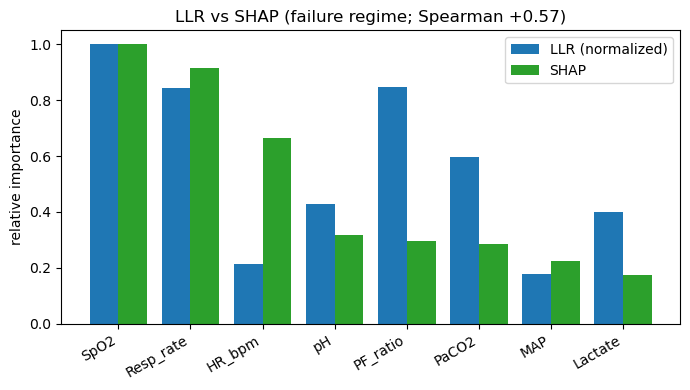

saved RF_PEMDT_output/explainability/llr_vs_shap.png ; Spearman = 0.571


In [2]:
# ============================================================
# Standalone · Respiratory LLR vs SHAP  (no pipeline cells required)
# ============================================================
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import spearmanr, norm
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
try:
    import shap as _shap; _HS = True
except Exception:
    _HS = False

BLUE, GREEN = "#1f77b4", "#2ca02c"
LIK_FEATURES = ["SpO2","Resp_rate","PF_ratio","PaCO2","pH","HR_bpm","MAP","Lactate"]
FEATURE_WEIGHTS = {"SpO2":1.6,"Resp_rate":1.4,"PF_ratio":1.8,"PaCO2":1.3,
                   "pH":1.1,"HR_bpm":0.8,"MAP":0.9,"Lactate":1.0}
STATE_Z = {"SpO2":[0.0,-1.5,-3.0],"Resp_rate":[0.0,1.5,3.0],"PF_ratio":[0.0,-1.2,-2.6],
           "PaCO2":[0.0,0.8,2.2],"pH":[0.0,-0.8,-2.0],"HR_bpm":[0.0,0.8,1.6],
           "MAP":[0.0,-0.6,-1.4],"Lactate":[0.0,0.8,1.8]}
STATE_SCALE = [1.0, 1.3, 1.6]

d = pd.read_csv("RF_PEMDT_output/RF_dashboard_cohort.csv", low_memory=False)
if len(d) > 300_000:                                   # subsample for speed
    d = d.sample(300_000, random_state=0).reset_index(drop=True)
feats = [f for f in LIK_FEATURES if f in d.columns]

X = d[feats].apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)
for f in feats:                                        # strip outliers so nothing overflows
    lo, hi = X[f].quantile([0.001, 0.999]); X[f] = X[f].clip(lo, hi)
X = X.fillna(X.median())
Yv = (d[["p_stable","p_compromise","p_failure"]].values.argmax(1) == 2).astype(int)

GLOBAL_STATS = {f: (float(X[f].mean()), float(X[f].std() or 1.0)) for f in feats}
llr = {}
for f in feats:
    mu, sd = GLOBAL_STATS[f]; z = (X[f].to_numpy() - mu) / sd; w = FEATURE_WEIGHTS[f]
    ll_s = w * norm.logpdf(z, STATE_Z[f][0], STATE_SCALE[0])
    ll_f = w * norm.logpdf(z, STATE_Z[f][2], STATE_SCALE[2])
    llr[f] = float(np.mean(np.abs(ll_f - ll_s)))
llr = pd.Series(llr)

gbm = GradientBoostingClassifier(max_depth=3, n_estimators=150, random_state=0).fit(X, Yv)
if _HS:
    r = _shap.TreeExplainer(gbm).shap_values(X)
    if isinstance(r, list): r = r[-1]
    r = np.asarray(r); r = r[:, :, -1] if r.ndim == 3 else r
    shap_imp = pd.Series(np.abs(r).mean(0), index=feats)
else:
    lin = LogisticRegression(max_iter=2000).fit(X, Yv)
    shap_imp = pd.Series(np.abs(lin.coef_[0]) * X.std().values, index=feats)

c = pd.DataFrame({"LLR": llr, "SHAP": shap_imp}).sort_values("SHAP", ascending=False)
rho = spearmanr(c["LLR"].rank(ascending=False), c["SHAP"].rank(ascending=False)).correlation
nz = lambda s: s / (s.max() if s.max() > 0 else 1.0)
xv = np.arange(len(c)); wd = 0.4
Path("RF_PEMDT_output/explainability").mkdir(parents=True, exist_ok=True)
plt.figure(figsize=(7, 4))
plt.bar(xv - wd/2, nz(c["LLR"]),  wd, label="LLR (normalized)", color=BLUE)
plt.bar(xv + wd/2, nz(c["SHAP"]), wd, label="SHAP", color=GREEN)
plt.xticks(xv, c.index, rotation=30, ha="right"); plt.ylabel("relative importance")
plt.title(f"LLR vs SHAP (failure regime; Spearman {rho:+.2f})"); plt.legend()
plt.tight_layout()
plt.savefig("RF_PEMDT_output/explainability/llr_vs_shap.png", dpi=150); plt.show()
print("saved RF_PEMDT_output/explainability/llr_vs_shap.png ; Spearman =", round(rho, 3))